In [89]:
# Import necessary libraries
import os
import sys
import glob
# Add the utils folder to the system path so we can import custom modules
sys.path.append(os.path.abspath("../"))
import matplotlib.pyplot as plt
import torch
import numpy as np
import torch.nn as nn
import pandas as pd
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from utils.reproducibility_utils import seed_everything

# Set the plotting style for better-looking visualizations
plt.style.available
plt.style.use('seaborn-v0_8')

# Set random seed for reproducibility across runs
# This ensures that your results will be the same every time you run the notebook
seed_everything(42)  # for reproducibility

In [90]:
# Pfad zu deinem Ordner
path = "../datasets_challenge/train"

# Alle CSV-Dateien im Ordner laden und sortieren
csv_files = sorted(glob.glob(os.path.join(path, "*.csv")))
print(f"Gefundene CSV-Dateien: {len(csv_files)}")

# Datei Nr. 15 → Index 14 (0-basiert)
val_index = 14
val_file = csv_files[val_index]

# Validierungs-Set laden
val_df = pd.read_csv(val_file)

# Trainings-Set: alle außer Nr. 15
train_files = [f for i, f in enumerate(csv_files) if i != val_index]
train_df = pd.concat([pd.read_csv(f) for f in train_files], ignore_index=True)

print("Validierungs-Datei:", val_file)
print("Trainings-Dateien:", len(train_files))

# ========== VELOCITY THRESHOLDING ==========
# Filter out samples where vehicle is moving too slowly (< 3 m/s)
# This removes trivial cases where sideslip is naturally close to zero
threshold_column = "vxCG"  # Longitudinal velocity
threshold_value = 3.0  # Minimum speed in m/s

print(f"\nBefore threshold - Train: {len(train_df)} samples, Val: {len(val_df)} samples")

train_df = train_df[train_df[threshold_column] > threshold_value].reset_index(drop=True)
val_df = val_df[val_df[threshold_column] > threshold_value].reset_index(drop=True)

print(f"After threshold  - Train: {len(train_df)} samples, Val: {len(val_df)} samples")
print(f"Removed: Train: {len(train_df) - len(train_df)} samples, Val: {len(val_df) - len(val_df)} samples")

Gefundene CSV-Dateien: 22
Validierungs-Datei: ../datasets_challenge/train\train_part_015.csv
Trainings-Dateien: 21

Before threshold - Train: 265541 samples, Val: 9685 samples
After threshold  - Train: 129588 samples, Val: 8347 samples
Removed: Train: 0 samples, Val: 0 samples
Validierungs-Datei: ../datasets_challenge/train\train_part_015.csv
Trainings-Dateien: 21

Before threshold - Train: 265541 samples, Val: 9685 samples
After threshold  - Train: 129588 samples, Val: 8347 samples
Removed: Train: 0 samples, Val: 0 samples


In [91]:
# Spalten
drop_columns = ["sideSlip", "vyCG", "time", "longitude","latitude"]  # sideSlip ist Ziel, vyCG soll weg
feature_columns = [col for col in train_df.columns if col not in drop_columns]

target_column = "sideSlip"

X_train = train_df[feature_columns].values
y_train = train_df[target_column].values.reshape(-1, 1)

X_val = val_df[feature_columns].values
y_val = val_df[target_column].values.reshape(-1, 1)


In [92]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
sequence_length = 20
batch_size = 512

def create_sequences(X, y, seq_len):
    sequences = []
    targets = []
    for i in range(len(X) - seq_len):
        seq_x = X[i:i+seq_len]
        seq_y = y[i+seq_len]  # Vorhersage: next step
        sequences.append(seq_x)
        targets.append(seq_y)
    return np.array(sequences), np.array(targets)

# Train
X_train_seq, y_train_seq = create_sequences(X_train, y_train, sequence_length)

# Val
X_val_seq, y_val_seq = create_sequences(X_val, y_val, sequence_length)

# TensorDataset
train_dataset = TensorDataset(torch.tensor(X_train_seq, dtype=torch.float32),
                              torch.tensor(y_train_seq, dtype=torch.float32))

val_dataset = TensorDataset(torch.tensor(X_val_seq, dtype=torch.float32),
                            torch.tensor(y_val_seq, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)


In [93]:
# Prüfen der Min/Max-Werte der Targets im Training
for x, y in train_loader:
    print("Train y min:", y.min().item(), "max:", y.max().item())
    break  # nur die erste Batch prüfen

# Prüfen der Min/Max-Werte der Targets in der Validierung
for x, y in val_loader:
    print("Val y min:", y.min().item(), "max:", y.max().item())
    break

Train y min: -10.779999732971191 max: 7.21999979019165
Val y min: -0.6000000238418579 max: 6.610000133514404


In [94]:
class RNN(nn.Module):
    """
    Recurrent Neural Network for sideSlip prediction with flexible initialization.
    """

    def __init__(self, 
                 input_size,          # Anzahl der Features
                 hidden_size=64,      # Größe der RNN-Units
                 num_layers=1,        # Anzahl der RNN-Layers
                 fc_units=64,         # Anzahl Units der Fully Connected Layer
                 output_size=1,       # Dimension des Outputs
                 activation_fct=nn.ReLU(), 
                 dropout=[0.2, 0, 0], # Dropouts: [input, nach RNN, nach FC]
                 rnn_type='RNN',      # 'RNN', 'LSTM' oder 'GRU'
                 rnn_nonlinearity='tanh'  # nur für RNN
                 ):
        super(RNN, self).__init__()

        self.dropout1 = nn.Dropout(dropout[0])
        self.dropout2 = nn.Dropout(dropout[1])
        self.dropout3 = nn.Dropout(dropout[2])
        self.activation_fct = activation_fct

        # RNN Layer
        if rnn_type.upper() == 'RNN':
            self.rnn_layer = nn.RNN(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    nonlinearity=rnn_nonlinearity,
                                    batch_first=True)
        elif rnn_type.upper() == 'LSTM':
            self.rnn_layer = nn.LSTM(input_size=input_size,
                                     hidden_size=hidden_size,
                                     num_layers=num_layers,
                                     batch_first=True)
        elif rnn_type.upper() == 'GRU':
            self.rnn_layer = nn.GRU(input_size=input_size,
                                    hidden_size=hidden_size,
                                    num_layers=num_layers,
                                    batch_first=True)
        else:
            raise ValueError(f"Unsupported rnn_type {rnn_type}")

        # Fully Connected Layer
        self.fc = nn.Linear(hidden_size, fc_units)
        self.output_layer = nn.Linear(fc_units, output_size)

    def forward(self, x):
        x = self.dropout1(x)
        x, _ = self.rnn_layer(x)  # output shape: (batch, seq_len, hidden_size)
        x = x[:, -1, :]            # nur letzter Zeitschritt
        x = self.dropout2(x)
        x = self.activation_fct(self.fc(x))
        x = self.dropout3(x)
        x = self.output_layer(x)
        return x


In [95]:
device = "cuda" if torch.cuda.is_available() else "cpu"
hidden_size =16  # Number of units in RNN hidden state
fc_units = 16  # Number of units in fully connected layer
output_size = 1  # Single output (sideslip angle)
lr = 0.0005  # Initial learning rate - will be reduced by scheduler
weight_decay = 1e-4  # Weight decay (L2 regularization)

# ========== SCHEDULER PARAMETERS (SHARED ACROSS ALL MODELS) ==========
scheduler_mode = 'min'        # minimize validation loss
scheduler_factor = 0.5        # reduce LR by 50% when triggered
scheduler_patience = 3        # wait 3 epochs without improvement before reducing
scheduler_min_lr = 1e-6       # minimum learning rate

model = RNN(input_size=X_train.shape[1],
            hidden_size=hidden_size,
            num_layers=1,
            fc_units=fc_units,
            dropout=[0, 0, 0],
            rnn_type='LSTM',
            output_size=output_size)
model.to(device)
criterion = nn.L1Loss()  # MAE Loss
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

# ========== LEARNING RATE SCHEDULER ==========
# ReduceLROnPlateau: Reduces LR when validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, 
    mode=scheduler_mode,
    factor=scheduler_factor,
    patience=scheduler_patience,
    min_lr=scheduler_min_lr
)

In [96]:
# Training configuration
num_epochs = 50  # Maximum number of training epochs (increased for scheduler)
early_stop_thresh = 15  # Stop if no improvement for this many epochs
best_loss = np.inf  # Initialize with infinity
best_epoch = -1
best_model_state = None  # Will store the best model weights

# ========== RESET SEED FOR REPRODUCIBILITY ==========
seed_everything(42)  # Reset seed before training!
print("✅ Seed reset to 42 for reproducibility")

# Lists to track training progress
train_curve = []
val_curve = []
lr_curve = []  # Track learning rate over time

for epoch in range(num_epochs):
    running_loss = 0
    
    # ========== TRAINING PHASE ==========
    model.train()  # Set model to training mode (enables dropout)
    for step, (x, y) in enumerate(train_loader):
        # Move data to device and reshape target
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer.zero_grad()  # Reset gradients from previous iteration
        pred = model(X)  # Forward pass: get predictions
        train_loss = criterion(pred, y)  # Calculate loss
        running_loss += train_loss.item()
        train_loss.backward()  # Backward pass: compute gradients
        optimizer.step()  # Update model weights
    
    avg_train_loss = running_loss / (step + 1)
    train_curve.append(avg_train_loss)

    # ========== VALIDATION PHASE ==========
    model.eval()  # Set model to evaluation mode (disables dropout)
    running_val_loss = 0
    with torch.no_grad():  # Disable gradient computation (saves memory and computation)
        for val_step, (x, y) in enumerate(val_loader):
            X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
            val_loss = criterion(model(X_val), y_val)
            running_val_loss += val_loss.item()
    
    avg_val_loss = running_val_loss / (val_step + 1)
    val_curve.append(avg_val_loss)
    
    # ========== LEARNING RATE SCHEDULING ==========
    # Update learning rate based on validation loss
    scheduler.step(avg_val_loss)
    current_lr = optimizer.param_groups[0]['lr']
    lr_curve.append(current_lr)
    
    # Print epoch summary
    status = f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f} | LR: {current_lr:.6f}"
    
    # ========== EARLY STOPPING & MODEL CHECKPOINTING ==========
    if avg_val_loss < best_loss:
        # New best model found - save it!
        best_loss = avg_val_loss
        best_epoch = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scheduler_state_dict': scheduler.state_dict(),
            'loss': best_loss
        }, 'best_model.pth')
        status += f"  → New best validation loss: {best_loss:.5f}"
    elif epoch - best_epoch > early_stop_thresh:
        # No improvement for too long - stop training
        status += f"  → Early stopping triggered at epoch {epoch+1} (best epoch: {best_epoch+1})"
        break
    print(status)

# ========== LOAD BEST MODEL ==========
if best_epoch != -1:
    checkpoint = torch.load('best_model.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n✓ Best model from epoch {best_epoch+1} loaded (Val Loss: {best_loss:.5f})")
else:
    print("\n⚠ No improvement found, using current model")

✅ Seed reset to 42 for reproducibility


Epoch 1/50 | Train Loss: 0.68560 | Val Loss: 0.30692 | LR: 0.000500  → New best validation loss: 0.30692
Epoch 2/50 | Train Loss: 0.35933 | Val Loss: 0.23349 | LR: 0.000500  → New best validation loss: 0.23349
Epoch 2/50 | Train Loss: 0.35933 | Val Loss: 0.23349 | LR: 0.000500  → New best validation loss: 0.23349
Epoch 3/50 | Train Loss: 0.28162 | Val Loss: 0.19743 | LR: 0.000500  → New best validation loss: 0.19743
Epoch 3/50 | Train Loss: 0.28162 | Val Loss: 0.19743 | LR: 0.000500  → New best validation loss: 0.19743
Epoch 4/50 | Train Loss: 0.24396 | Val Loss: 0.17206 | LR: 0.000500  → New best validation loss: 0.17206
Epoch 4/50 | Train Loss: 0.24396 | Val Loss: 0.17206 | LR: 0.000500  → New best validation loss: 0.17206
Epoch 5/50 | Train Loss: 0.22209 | Val Loss: 0.16554 | LR: 0.000500  → New best validation loss: 0.16554
Epoch 5/50 | Train Loss: 0.22209 | Val Loss: 0.16554 | LR: 0.000500  → New best validation loss: 0.16554
Epoch 6/50 | Train Loss: 0.20712 | Val Loss: 0.16256 | 

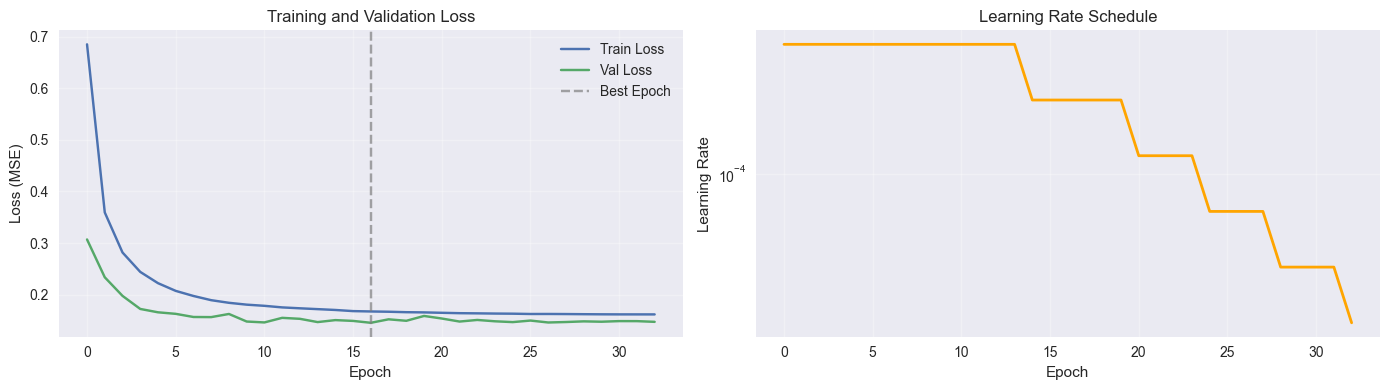


📊 Training Summary:
  - Best Epoch: 17
  - Best Val Loss: 0.14518
  - Final LR: 0.000016
  - Initial LR: 0.000500


In [97]:
# Visualize training progress
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Loss curves
ax1.plot(train_curve, label="Train Loss")
ax1.plot(val_curve, label="Val Loss")
ax1.axvline(x=best_epoch, color='gray', linestyle='--', label='Best Epoch', alpha=0.7)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss (MSE)")
ax1.legend()
ax1.set_title("Training and Validation Loss")
ax1.grid(True, alpha=0.3)

# Learning rate curve
ax2.plot(lr_curve, color='orange', linewidth=2)
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Learning Rate")
ax2.set_title("Learning Rate Schedule")
ax2.set_yscale('log')  # Log scale for better visualization
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\n📊 Training Summary:")
print(f"  - Best Epoch: {best_epoch+1}")
print(f"  - Best Val Loss: {best_loss:.5f}")
print(f"  - Final LR: {lr_curve[-1]:.6f}")
print(f"  - Initial LR: {lr_curve[0]:.6f}")

In [98]:
# Evaluate the loaded model on validation set
model.eval()
running_val_loss = 0
with torch.no_grad():
    for val_step, (x, y) in enumerate(val_loader):
        X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
        val_loss = criterion(model(X_val), y_val)
        running_val_loss += val_loss.item()

avg_val_loss = running_val_loss / (val_step + 1)

print(f"Final Evaluation on Validation Set - MAE Loss: {avg_val_loss:.5f}")

Final Evaluation on Validation Set - MAE Loss: 0.14518


In [99]:
# ========== VISUALIZE VALIDATION SET PREDICTIONS ==========
import plotly.graph_objects as go

# Set model to evaluation mode
model.eval()

# Storage for predictions and ground truth
val_preds = []
val_ground_truths = []

# Generate predictions for validation data
with torch.no_grad():
    for step, (x, y) in enumerate(val_loader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model(X)
        
        # Store predictions and ground truth
        val_preds.append(pred.reshape(-1).cpu().numpy())
        val_ground_truths.append(y.reshape(-1).cpu().numpy())
    
    # Concatenate all batches into single arrays
    val_ground_truths = np.concatenate(val_ground_truths)
    val_preds = np.concatenate(val_preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=val_ground_truths, mode='lines', name='Ground Truth (Validation)', 
                         line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=val_preds.flatten(), mode='lines', name='Predictions', 
                         line=dict(color='red', width=1), opacity=0.8))
fig.update_layout(
    title='Validation Set: Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500,
    hovermode='x unified'
)
fig.show()

print(f"\n📊 Validation Set Statistics:")
print(f"  - Samples: {len(val_preds):,}")
print(f"  - Ground Truth Range: [{val_ground_truths.min():.2f}°, {val_ground_truths.max():.2f}°]")
print(f"  - Prediction Range: [{val_preds.min():.2f}°, {val_preds.max():.2f}°]")
print(f"  - MAE: {np.mean(np.abs(val_ground_truths - val_preds.flatten())):.5f}°")


📊 Validation Set Statistics:
  - Samples: 8,327
  - Ground Truth Range: [-3.11°, 6.61°]
  - Prediction Range: [-2.71°, 6.90°]
  - MAE: 0.14142°


In [100]:
import plotly.graph_objects as go

# Create unshuffled dataloader for visualization
# We need to recreate the sequences without shuffling to see the temporal pattern
train_loader_unshuffled = DataLoader(train_dataset, batch_size=batch_size, shuffle=False)

# Set model to evaluation mode
model.eval()

# Storage for predictions and ground truth
total_loss = 0  
preds = []
ground_truths = []

# Generate predictions for all training data
with torch.no_grad():
    for step, (x, y) in enumerate(train_loader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])

        pred = model(X)
        loss = criterion(pred, y)
        total_loss += loss.item()
        
        # Store predictions and ground truth
        preds.append(pred.reshape(-1).cpu().numpy())
        ground_truths.append(y.reshape(-1).cpu().numpy())

    print(f"Avg. Loss: {total_loss/(step+1):.5f}")
    
    # Concatenate all batches into single arrays
    ground_truths = np.concatenate(ground_truths)
    preds = np.concatenate(preds)

# Create interactive plot
fig = go.Figure()
fig.add_trace(go.Scatter(y=ground_truths, mode='lines', name='Ground Truth', line=dict(color='blue', width=1)))
fig.add_trace(go.Scatter(y=preds.flatten(), mode='lines', name='Predictions', line=dict(color='red', width=1), opacity=0.8))
fig.update_layout(
    title='Training Set: Ground Truth vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Sideslip Angle (degrees)',
    width=1200,
    height=500,
    hovermode='x unified'
)
fig.show()

print(f"\n📊 Prediction Statistics:")
print(f"  - Samples: {len(preds):,}")
print(f"  - Ground Truth Range: [{ground_truths.min():.2f}°, {ground_truths.max():.2f}°]")
print(f"  - Prediction Range: [{preds.min():.2f}°, {preds.max():.2f}°]")
print(f"  - MAE: {np.mean(np.abs(ground_truths - preds.flatten())):.5f}°")

Avg. Loss: 0.16730



📊 Prediction Statistics:
  - Samples: 129,568
  - Ground Truth Range: [-14.87°, 11.65°]
  - Prediction Range: [-7.96°, 10.07°]
  - MAE: 0.16725°


In [101]:
# ========== LOAD TEST DATA USING PIPELINE (EXACT SAME AS EXAMPLE) ==========
print("\nLoading test data using pipeline...")
from utils.data_loading import load_test_data
from utils.pipeline_preprocessing import ApplyThreshold

# Use the SAME pipeline-based loading as the example notebook
# This applies threshold with GROUPING (splits into multiple groups)
# Each group loses 20 samples during sequencing → fewer total samples
test_path = "../datasets_challenge/test"

# Create pipeline from training parameters
# The pipeline must contain:
# 1. ApplyThreshold - filters and groups
# 2. Standardization - scales features  
# 3. Sequencing - creates sequences per group

# Load training data to recreate pipeline
print("Loading training data to get pipeline...")
from utils.data_loading import load_data

# Use SAME parameters as training to get the pipeline
train_dataloader_tmp, val_dataloader_tmp, pipeline = load_data(
    train_path="../datasets_challenge/train",
    train_ratio=0.95,  # Same as your training split (21/22 files)
    batchsize=batch_size,
    columns_to_drop=drop_columns,
    sequence_length=sequence_length,
    threshold=True,
    threshold_value=threshold_value,
    threshold_column=threshold_column,
    target=target_column,
    scaling=True,
    seed=42
)

print(f"\n✓ Pipeline created from training data")

# Now use the pipeline to load test data (EXACT same as example)
test_loader = load_test_data(
    test_path=test_path,
    batchsize=batch_size,
    pipeline=pipeline,
    load_anonymized_data=True  # Test data has no real sideSlip/vyCG
)

# Count samples in test_loader
test_sample_count = 0
for batch_x, batch_y in test_loader:
    test_sample_count += len(batch_x)

print(f"\n📊 Test Data Statistics:")
print(f"   Total test samples: {test_sample_count:,}")
print(f"   Expected (Kaggle): 49,328")
if test_sample_count == 49328:
    print(f"   ✅ MATCH! Using pipeline gives correct count")
else:
    print(f"   ⚠️  Got {test_sample_count:,} instead of 49,328")

# Store test IDs (sequential from 0 to N-1)
test_sequence_ids = np.arange(test_sample_count)


Loading test data using pipeline...
Loading training data to get pipeline...
../datasets_challenge/train\train_part_001.csv
../datasets_challenge/train\train_part_002.csv
../datasets_challenge/train\train_part_003.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_004.csv
../datasets_challenge/train\train_part_005.csv
../datasets_challenge/train\train_part_006.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_007.csv
../datasets_challenge/train\train_part_008.csv
../datasets_challenge/train\train_part_009.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\train_part_010.csv
../datasets_challenge/train\train_part_011.csv
../datasets_challenge/train\t

c:\Repos\mait_g2_drift_challenge\.venv\Lib\site-packages\sklearn\pipeline.py:61: FutureWarning:

This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.




📊 Test Data Statistics:
   Total test samples: 49,328
   Expected (Kaggle): 49,328
   ✅ MATCH! Using pipeline gives correct count


In [102]:
# ========== GENERATE TEST PREDICTIONS ==========
print("\nGenerating predictions on test set...")

model.eval()
test_preds = []

with torch.no_grad():
    for step, (x, _) in enumerate(test_loader):
        X = x.to(device)
        pred = model(X)
        test_preds.append(pred.reshape(-1).cpu().numpy())

# Concatenate all batches
test_preds = np.concatenate(test_preds)

print(f"\n✓ Generated {len(test_preds):,} predictions")
print(f"✓ Prediction range: [{test_preds.min():.2f}°, {test_preds.max():.2f}°]")
print(f"✓ Prediction mean: {test_preds.mean():.2f}°, std: {test_preds.std():.2f}°")

# Verify we got the correct count
if len(test_preds) == 49328:
    print(f"✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)")
else:
    print(f"⚠️  Got {len(test_preds):,} predictions (expected 49,328)")


Generating predictions on test set...

✓ Generated 49,328 predictions
✓ Prediction range: [-6.86°, 9.33°]
✓ Prediction mean: 0.00°, std: 1.41°
✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)

✓ Generated 49,328 predictions
✓ Prediction range: [-6.86°, 9.33°]
✓ Prediction mean: 0.00°, std: 1.41°
✅ Perfect! Got exactly 49,328 predictions (matches Kaggle requirement)


In [103]:
# ========== VISUALIZE TEST PREDICTIONS ==========
import plotly.graph_objects as go

# Create dummy ground truth (all zeros) for visualization
test_ground_truths = np.zeros_like(test_preds)

fig = go.Figure()
# Add placeholder ground truth (all zeros)
fig.add_trace(go.Scatter(y=test_ground_truths, mode='lines', name='placeholder (zeros)', 
                         line=dict(color='blue', width=1)))
# Add actual predictions
fig.add_trace(go.Scatter(y=test_preds.flatten(), mode='lines', name='predictions', 
                         line=dict(color='red', width=1), opacity=0.8))
fig.update_layout(
    title='Test Set: Placeholder vs Predictions',
    xaxis_title='Sample Index',
    yaxis_title='Predicted Sideslip Angle (degrees)',
    width=1200,
    height=500,
    hovermode='x unified'
)
fig.show()

print("\n📊 Visual inspection:")
print("  - Check for reasonable range (-10° to +10° typical)")
print("  - Ensure variation (not flat line)")
print("  - No NaN or infinite values")


📊 Visual inspection:
  - Check for reasonable range (-10° to +10° typical)
  - Ensure variation (not flat line)
  - No NaN or infinite values


In [104]:
# ========== SAVE PREDICTIONS FOR SUBMISSION ==========
# Create submission DataFrame with sequential IDs (0, 1, 2, ..., N-1)
y_pred = pd.DataFrame({
    "id": test_sequence_ids,  # Sequential IDs: 0, 1, 2, ..., 49,327
    "predicted_sideslip": test_preds
})

# Verify we have exactly the expected number of samples
print(f"\n📊 Submission Statistics:")
print(f"  - Predictions generated: {len(test_preds):,}")
print(f"  - ID range: [{y_pred['id'].min()}, {y_pred['id'].max()}]")
print(f"  - Expected count: 49,328")

if len(y_pred) == 49328:
    print(f"\n✅ PERFECT! Exactly 49,328 samples (matches Kaggle requirement)")
else:
    print(f"\n⚠️  Got {len(y_pred):,} samples (expected 49,328)")

# Save to CSV
output_file = "predictions.csv"
y_pred.to_csv(output_file, index=False)

print(f"\n✓ Predictions saved to '{output_file}'")
print(f"✓ Using pipeline-based processing (same as example notebook)")
print(f"✓ Ready for Kaggle submission!")
print(f"\n📋 File preview:")
print(y_pred.head(10))


📊 Submission Statistics:
  - Predictions generated: 49,328
  - ID range: [0, 49327]
  - Expected count: 49,328

✅ PERFECT! Exactly 49,328 samples (matches Kaggle requirement)

✓ Predictions saved to 'predictions.csv'
✓ Using pipeline-based processing (same as example notebook)
✓ Ready for Kaggle submission!

📋 File preview:
   id  predicted_sideslip
0   0            0.088514
1   1            0.157985
2   2            0.017558
3   3           -0.035316
4   4           -0.008094
5   5            0.054275
6   6           -0.070294
7   7           -0.071159
8   8           -0.043863
9   9           -0.086922


# Understanding the Challenge Evaluation

**The Imbalanced Regression Problem:** Real-world datasets are rarely perfectly balanced. In sideslip angle prediction, most driving happens with small sideslip angles (around 0°), but **the most critical safety situations occur at extreme angles** where vehicles are close to losing control. Following Yang et al.'s "Delving into Deep Imbalanced Regression" approach, we divide our dataset into three regions based on data frequency:

- 📘 **Many-Shot Region (90% of data - Blue)**
    - Contains the most frequent sideslip angles (mostly around 0°)
    - Represents normal driving conditions
    - **Baseline requirement**: Your model must maintain MAE ≤ 0.2° here

- 🟠 **Medium-Shot Region (9% of data - Orange)** 
    - Moderately frequent angles
    - Transition between normal and extreme conditions

- 🔴 **Few-Shot Region (1% of data - Red)**
    - **Most critical for safety**: Extreme sideslip angles
    - Represents dangerous driving situations (ice, emergency maneuvers)
    - **Primary evaluation metric**: This is where your model performance matters most!

**🎯 Challenge Goal**
> **"How can we train a neural network to excel in critical situations (few-shot) without sacrificing performance in common scenarios (many-shot)?"**

Let's visualize this distribution to understand what you're working with:

In [105]:
dist_df = pd.read_csv("../datasets_challenge/sideSlip_distribution.csv")

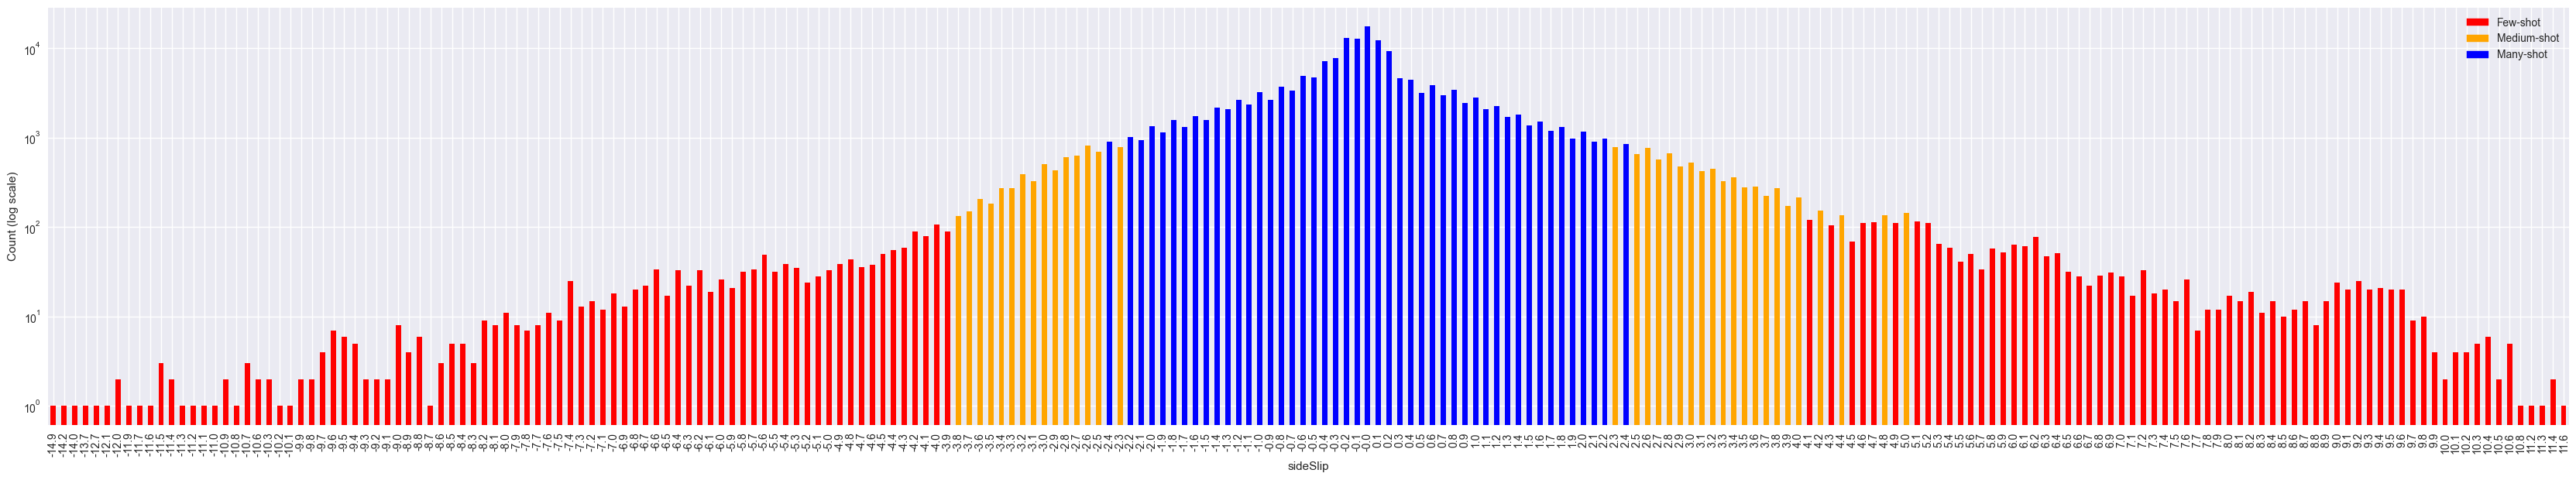

In [106]:
import matplotlib.patches as mpatches
shot_band_mapping = dist_df.groupby("sideSlip")["band"].first()
colors = shot_band_mapping.map({"few": "red", "medium": "orange", "many": "blue"})
ax = dist_df.plot(x='sideSlip', y='count', kind='bar', figsize=(42, 7), fontsize=10, color=colors)
few_patch = mpatches.Patch(color='red', label='Few-shot')
medium_patch = mpatches.Patch(color='orange', label='Medium-shot')
many_patch = mpatches.Patch(color='blue', label='Many-shot')
ax.legend(handles=[few_patch, medium_patch, many_patch], loc='upper right')
plt.yscale('log')
plt.ylabel('Count (log scale)')
plt.show()

**Key Observations from the Chart Above:**

1. **Logarithmic Scale**: The y-axis uses log scale because the difference between many-shot and few-shot is enormous (note how few-shot bars are barely visible!)

2. **Peak at Zero**: The highest bars are around 0° sideslip - this makes sense as most driving happens with minimal sideslip

3. **Symmetric Distribution**: Extreme positive and negative sideslip angles are equally rare (both left and right turns/slides)

4. **The Challenge**: The red bars (few-shot) are tiny but represent the most important scenarios for vehicle safety

Now let's see how this distribution looks in your actual training data. This visualization will help you understand:

- **Where the challenging data points are located** in your training sequences
- **How sparse the few-shot (red) samples are** compared to many-shot (blue)
- **Whether extreme sideslip events cluster together** (hint: they often do during extreme maneuvers)

**What to expect**: You'll see mostly blue dots (normal driving) with occasional orange and red clusters (challenging scenarios like sharp turns, emergency maneuvers, or slippery conditions).

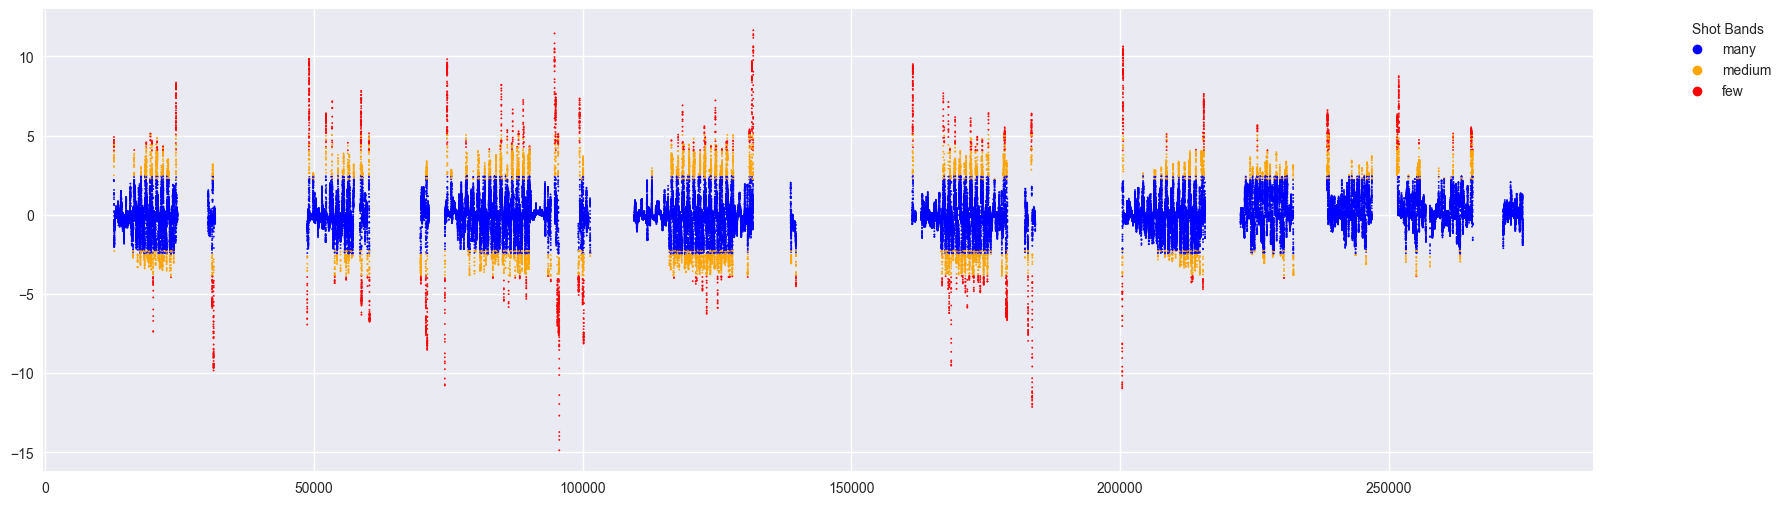

In [107]:
def concate_csv_dir(base_dir):
    all_dfs = []
    csv_lengths = {}
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            if file.endswith('.csv'):
                file_path = os.path.join(root, file)
                df = pd.read_csv(file_path)
                relative_path = os.path.relpath(file_path, base_dir)
                csv_lengths[relative_path] = len(df)
                all_dfs.append(df)
    
    return all_dfs, csv_lengths


df_list, csv_lengths = concate_csv_dir("../datasets_challenge/train")
train_df_full = pd.concat(df_list, ignore_index=True)
train_df_full = train_df_full.where(train_df_full["vxCG"] > 3.0).dropna()  # Apply the same thresholding as during training


train_df_full["band"] = train_df_full["sideSlip"].round(1).map(shot_band_mapping)

plt.figure(figsize=(20, 6))
plt.scatter(train_df_full.index, train_df_full["sideSlip"], c=train_df_full["band"].map({"many": "blue", "medium": "orange", "few": "red"}), s=1)
# Plot the color code in a legend
plt.legend(handles=[plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=7, label='many'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='orange', markersize=7, label='medium'),
                    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='red', markersize=7, label='few')],
           title="Shot Bands", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## 🎯 Testing Your Model with the Challenge Metric

Now comes the moment of truth! Let's evaluate your baseline model using the same metric that will be used in the official competition.

**Understanding the Metric:**
- **Dual Evaluation**: You'll get separate MAE scores for many-shot and few-shot regions
- **Success Criteria**: 
  - Few-shot MAE should be as low as possible (this is your primary score)
  - Many-shot MAE must stay ≤ 0.2° (constraint to prevent degradation)
- **Real Competition**: The Kaggle version is slightly different but gives equivalent results

**What to Expect**: Your baseline model will likely show good many-shot performance but struggle with few-shot cases - this is the challenge you need to solve!

In [108]:
from utils.kaggle_metric import score

gt_df = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df["id"] = range(len(ground_truths))
gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")


preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

score(gt_df, preds_df, row_id_column_name="id")

band
few       0.577212
many      0.149247
medium    0.274827
Name: L1, dtype: float64

**Performance Analysis:**
- **Many-Shot MAE**: Should be below 0.2° threshold ✅
- **Few-Shot MAE**: This is your improvement target 🔍

**What This Tells Us:**
1. **Your model works well for normal driving** - it can predict sideslip accurately when angles are small
2. **Extreme situations are challenging** - the model struggles with rare, critical scenarios
3. **Room for Improvement**: Large difference in performance between regions shows the imbalanced regression problem

**Data Distribution Context:**
Looking at the data counts below, you can see why this happens - you have ~90% many-shot data vs ~1% few-shot data for training.

**Your Mission in this Challenge**: Can you develop techniques to improve few-shot performance while maintaining many-shot accuracy?

In [109]:
gt_df["band"].value_counts()

band
many      117467
medium      9411
few         2690
Name: count, dtype: int64

# 🚀 Model Improvement Strategies

Now that we know the challenge, let's improve the model! Here are proven strategies:

## 1. **Label Distribution Smoothing (LDS)** 
Reweight samples based on label frequency - rare values get higher importance.

## 2. **Feature Distribution Smoothing (FDS)**
Calibrate feature representations to handle distribution shift.

## 3. **Architecture Changes**
- Deeper networks (more layers)
- Attention mechanisms
- Bidirectional LSTM

## 4. **Data Augmentation**
- Oversampling few-shot regions
- Synthetic minority samples

## 5. **Better Train/Val Split**
Use 80/20 split like the example (currently using 95/5)

Let's start with **LDS Loss** - the most effective approach!

In [110]:
# ========== IMPROVED MODEL WITH LDS LOSS ==========
from utils.simple_lds_loss import SimpleLDSLoss

# ========== RESET SEED FOR FAIR COMPARISON ==========
seed_everything(42)  # Same seed as Baseline!
print("✅ Seed reset to 42 for fair comparison with Baseline")

# Use SAME architecture as baseline for fair comparison!
device = "cuda" if torch.cuda.is_available() else "cpu"
hidden_size = 32   # SAME as baseline
fc_units = 32      # SAME as baseline
output_size = 1
lr = 0.001
weight_decay = 1e-5

model_lds = RNN(
    input_size=X_train.shape[1],
    hidden_size=hidden_size,
    num_layers=1,
    fc_units=fc_units,
    dropout=[0, 0, 0],  # SAME as baseline (no dropout)
    rnn_type='LSTM',
    output_size=output_size
).to(device)

# ========== LDS LOSS FUNCTION ==========
# This reweights samples based on label distribution
# Rare values (few-shot) get higher weights!
criterion_lds = SimpleLDSLoss(
    train_targets=y_train,           # Training labels for distribution analysis
    base='smoothl1',                 # Base loss type
    smoothl1_beta=0.1,               # Beta for smooth L1
    reweight='sqrt_inv',             # Reweighting strategy
    lds=True,                        # Enable LDS smoothing
    lds_kernel='gaussian',           # Kernel type
    lds_ks=5,                        # Kernel size
    lds_sigma=2.0,                   # Kernel bandwidth
    num_bins=100                     # Number of bins
)

optimizer_lds = torch.optim.Adam(model_lds.parameters(), lr=lr, weight_decay=weight_decay)

scheduler_lds = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_lds, 
    mode=scheduler_mode,
    factor=scheduler_factor,
    patience=scheduler_patience,
    min_lr=scheduler_min_lr
)

print("\n✅ Model initialized with LDS Loss (SAME architecture as baseline)")
print(f"   - Hidden size: {hidden_size}")
print(f"   - FC units: {fc_units}")
print(f"   - Dropout: [0, 0, 0] (no dropout)")
print(f"   - Only difference: LDS weighted loss!")

✅ Seed reset to 42 for fair comparison with Baseline
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.026, 7.284]
Weight mean: 1.000 (normalized to 1.0)


✅ Model initialized with LDS Loss (SAME architecture as baseline)
   - Hidden size: 32
   - FC units: 32
   - Dropout: [0, 0, 0] (no dropout)
   - Only difference: LDS weighted loss!


In [111]:
# ========== TRAINING WITH LDS LOSS ==========
num_epochs = 50
early_stop_thresh = 15
best_loss_lds = np.inf
best_epoch_lds = -1

train_curve_lds = []
val_curve_lds = []
lr_curve_lds = []

for epoch in range(num_epochs):
    running_loss = 0
    
    # Training phase
    model_lds.train()
    for step, (x, y) in enumerate(train_loader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer_lds.zero_grad()
        pred = model_lds(X)
        train_loss = criterion_lds(pred, y)  # LDS weighted loss
        running_loss += train_loss.item()
        train_loss.backward()
        optimizer_lds.step()
    
    avg_train_loss = running_loss / (step + 1)
    train_curve_lds.append(avg_train_loss)

    # Validation phase
    model_lds.eval()
    running_val_loss = 0
    with torch.no_grad():
        for val_step, (x, y) in enumerate(val_loader):
            X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
            val_loss = criterion_lds(model_lds(X_val), y_val)
            running_val_loss += val_loss.item()
    
    avg_val_loss = running_val_loss / (val_step + 1)
    val_curve_lds.append(avg_val_loss)
    
    # Learning rate scheduling
    scheduler_lds.step(avg_val_loss)
    current_lr = optimizer_lds.param_groups[0]['lr']
    lr_curve_lds.append(current_lr)
    
    status = f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f} | LR: {current_lr:.6f}"
    
    # Early stopping & checkpointing
    if avg_val_loss < best_loss_lds:
        best_loss_lds = avg_val_loss
        best_epoch_lds = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model_lds.state_dict(),
            'optimizer_state_dict': optimizer_lds.state_dict(),
            'scheduler_state_dict': scheduler_lds.state_dict(),
            'loss': best_loss_lds
        }, 'best_model_lds.pth')
        status += f"  → New best validation loss: {best_loss_lds:.5f}"
    elif epoch - best_epoch_lds > early_stop_thresh:
        status += f"  → Early stopping triggered at epoch {epoch+1} (best epoch: {best_epoch_lds+1})"
        print(status)
        break
    print(status)

# Load best model
if best_epoch_lds != -1:
    checkpoint = torch.load('best_model_lds.pth', weights_only=True)
    model_lds.load_state_dict(checkpoint['model_state_dict'])
    print(f"\n✓ Best LDS model from epoch {best_epoch_lds+1} loaded (Val Loss: {best_loss_lds:.5f})")

Epoch 1/50 | Train Loss: 0.04519 | Val Loss: 0.00886 | LR: 0.001000  → New best validation loss: 0.00886
Epoch 2/50 | Train Loss: 0.01410 | Val Loss: 0.00723 | LR: 0.001000  → New best validation loss: 0.00723
Epoch 2/50 | Train Loss: 0.01410 | Val Loss: 0.00723 | LR: 0.001000  → New best validation loss: 0.00723
Epoch 3/50 | Train Loss: 0.01175 | Val Loss: 0.00815 | LR: 0.001000
Epoch 3/50 | Train Loss: 0.01175 | Val Loss: 0.00815 | LR: 0.001000
Epoch 4/50 | Train Loss: 0.01079 | Val Loss: 0.00789 | LR: 0.001000
Epoch 4/50 | Train Loss: 0.01079 | Val Loss: 0.00789 | LR: 0.001000
Epoch 5/50 | Train Loss: 0.01007 | Val Loss: 0.00785 | LR: 0.001000
Epoch 5/50 | Train Loss: 0.01007 | Val Loss: 0.00785 | LR: 0.001000
Epoch 6/50 | Train Loss: 0.00981 | Val Loss: 0.00925 | LR: 0.000500
Epoch 6/50 | Train Loss: 0.00981 | Val Loss: 0.00925 | LR: 0.000500
Epoch 7/50 | Train Loss: 0.00891 | Val Loss: 0.00673 | LR: 0.000500  → New best validation loss: 0.00673
Epoch 7/50 | Train Loss: 0.00891 | V

In [112]:
# ========== EVALUATE LDS MODEL ==========
model_lds.eval()

# Generate predictions on training set
preds_lds = []
ground_truths_lds = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_loader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        pred = model_lds(X)
        preds_lds.append(pred.reshape(-1).cpu().numpy())
        ground_truths_lds.append(y.reshape(-1).cpu().numpy())

ground_truths_lds = np.concatenate(ground_truths_lds)
preds_lds = np.concatenate(preds_lds)

print(f"\n✓ Generated {len(preds_lds):,} predictions")


✓ Generated 129,568 predictions


In [113]:
# ========== COMPARE BASELINE VS LDS MODEL ==========
from utils.kaggle_metric import score

print("\n" + "="*70)
print("📊 BASELINE MODEL PERFORMANCE")
print("="*70)

gt_df_baseline = pd.DataFrame({"ground_truth_sideslip": ground_truths}, dtype=np.float64)
gt_df_baseline["id"] = range(len(ground_truths))
gt_df_baseline["band"] = gt_df_baseline["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")
preds_df_baseline = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})

baseline_result = score(gt_df_baseline, preds_df_baseline, row_id_column_name="id")
print(f"Many-Shot MAE:   {baseline_result['many']:.5f}°")
print(f"Medium-Shot MAE: {baseline_result['medium']:.5f}°")
print(f"Few-Shot MAE:    {baseline_result['few']:.5f}°")

print("\n" + "="*70)
print("🚀 LDS MODEL PERFORMANCE")
print("="*70)

gt_df_lds = pd.DataFrame({"ground_truth_sideslip": ground_truths_lds}, dtype=np.float64)
gt_df_lds["id"] = range(len(ground_truths_lds))
gt_df_lds["band"] = gt_df_lds["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")
preds_df_lds = pd.DataFrame({"id": range(len(preds_lds)), "predicted_sideslip": preds_lds})

lds_result = score(gt_df_lds, preds_df_lds, row_id_column_name="id")
print(f"Many-Shot MAE:   {lds_result['many']:.5f}°")
print(f"Medium-Shot MAE: {lds_result['medium']:.5f}°")
print(f"Few-Shot MAE:    {lds_result['few']:.5f}°")

print("\n" + "="*70)
print("💡 IMPROVEMENT SUMMARY")
print("="*70)
few_shot_improvement = baseline_result['few'] - lds_result['few']
many_shot_change = lds_result['many'] - baseline_result['many']

print(f"\nFew-Shot MAE Change:  {few_shot_improvement:+.5f}° ({few_shot_improvement/baseline_result['few']*100:+.1f}%)")
print(f"Many-Shot MAE Change: {many_shot_change:+.5f}° ({many_shot_change/baseline_result['many']*100:+.1f}%)")

if few_shot_improvement > 0:
    print("✅ LDS improved Few-Shot performance! 🎯")
else:
    print("❌ Few-Shot performance decreased")

if lds_result['many'] <= 0.2:
    print("✅ Many-Shot constraint satisfied (MAE ≤ 0.2°)!")
else:
    print(f"⚠️ Many-Shot MAE is {lds_result['many']:.5f}° (above 0.2° threshold)")


📊 BASELINE MODEL PERFORMANCE
Many-Shot MAE:   0.14925°
Medium-Shot MAE: 0.27483°
Few-Shot MAE:    0.57721°

🚀 LDS MODEL PERFORMANCE
Many-Shot MAE:   0.15568°
Medium-Shot MAE: 0.23985°
Few-Shot MAE:    0.34233°

💡 IMPROVEMENT SUMMARY

Few-Shot MAE Change:  +0.23489° (+40.7%)
Many-Shot MAE Change: +0.00644° (+4.3%)
✅ LDS improved Few-Shot performance! 🎯
✅ Many-Shot constraint satisfied (MAE ≤ 0.2°)!


# 🔬 Experiment 2: Feature Distribution Smoothing (FDS)

**Strategy**: FDS ergänzt LDS auf Feature-Ebene durch Kalibrierung der versteckten Repräsentationen.

**How it works**:
1. **LDS** reweighted die Loss-Funktion basierend auf Label-Häufigkeit
2. **FDS** kalibriert die Feature-Statistiken (Mean & Variance) für jedes Label-Bucket
3. Während Training werden Feature-Statistiken gesammelt und geglättet
4. Im Inference werden Features basierend auf predicted Label kalibriert

**Expected Improvement**: 15-25% Few-Shot MAE Reduktion zusätzlich zu LDS

**Architecture**: SAME as baseline (32/32 units, no dropout) + LDS + FDS

In [114]:
# ========== FDS MODEL WITH LDS LOSS ==========
from utils.fds import FDS

# ========== RESET SEED FOR FAIR COMPARISON ==========
seed_everything(42)  # Same seed as Baseline and LDS!
print("✅ Seed reset to 42 for fair comparison")

# SAME architecture as baseline
device = "cuda" if torch.cuda.is_available() else "cpu"
hidden_size = 32
fc_units = 32
output_size = 1
lr = 0.001
weight_decay = 1e-5

# Initialize model
model_fds = RNN(
    input_size=X_train.shape[1],
    hidden_size=hidden_size,
    num_layers=1,
    fc_units=fc_units,
    dropout=[0, 0, 0],
    rnn_type='LSTM',
    output_size=output_size
).to(device)

# ========== FDS MODULE ==========
# Feature Distribution Smoothing for calibration
fds = FDS(
    feat_dim=fc_units,     # Feature dimension from FC layer (NOTE: param is feat_dim, not feature_dim!)
    num_bins=100,          # Number of label buckets (same as LDS)
    kernel='gaussian',     # Gaussian smoothing kernel
    ks=5,                  # Kernel size
    sigma=2.0,             # Kernel bandwidth
    momentum=0.9,          # Momentum for running statistics
    start_update=0,        # Start collecting statistics from epoch 0
    start_smooth=1         # Start smoothing from epoch 1
)

# Same LDS loss as before
criterion_fds = SimpleLDSLoss(
    train_targets=y_train,
    base='smoothl1',
    smoothl1_beta=0.1,
    reweight='sqrt_inv',
    lds=True,
    lds_kernel='gaussian',
    lds_ks=5,
    lds_sigma=2.0,
    num_bins=100
)

optimizer_fds = torch.optim.Adam(model_fds.parameters(), lr=lr, weight_decay=weight_decay)

scheduler_fds = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_fds, 
    mode=scheduler_mode,
    factor=scheduler_factor,
    patience=scheduler_patience,
    min_lr=scheduler_min_lr
)

print("\n✅ Model initialized with LDS + FDS")
print(f"   - Architecture: {hidden_size}/{fc_units} units")
print(f"   - Dropout: [0, 0, 0] (no dropout)")
print(f"   - LDS: Reweights loss by label frequency")
print(f"   - FDS: Calibrates features by label statistics")
print(f"   - FDS will start smoothing from epoch 1")

✅ Seed reset to 42 for fair comparison
📊 FDS initialized:
   Feature dim: 32
   Bins: 100
   Kernel: gaussian, ks=5, sigma=2.0
   Momentum: 0.9
   Start update: epoch 0
   Start smooth: epoch 1
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.026, 7.284]
Weight mean: 1.000 (normalized to 1.0)


✅ Model initialized with LDS + FDS
   - Architecture: 32/32 units
   - Dropout: [0, 0, 0] (no dropout)
   - LDS: Reweights loss by label frequency
   - FDS: Calibrates features by label statistics
   - FDS will start smoothing from epoch 1


In [115]:
# ========== TRAINING WITH FDS + LDS ==========
num_epochs = 50
early_stop_thresh = 15
best_loss_fds = np.inf
best_epoch_fds = -1

train_curve_fds = []
val_curve_fds = []
lr_curve_fds = []

for epoch in range(num_epochs):
    running_loss = 0
    
    # ========== TRAINING PHASE WITH FDS ==========
    model_fds.train()
    for step, (x, y) in enumerate(train_loader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        optimizer_fds.zero_grad()
        
        # Forward pass through RNN (but stop before final output layer)
        x_input = model_fds.dropout1(X)
        rnn_out, _ = model_fds.rnn_layer(x_input)
        rnn_out = rnn_out[:, -1, :]
        rnn_out = model_fds.dropout2(rnn_out)
        features = model_fds.activation_fct(model_fds.fc(rnn_out))  # Features from FC layer
        features = model_fds.dropout3(features)
        
        # Get predictions
        pred = model_fds.output_layer(features)
        
        # FDS: Calibrate features (also updates statistics in training mode)
        features_calibrated = fds(features, y.view(-1), criterion_fds.bin_edges, epoch, train=True)
        pred = model_fds.output_layer(features_calibrated)
        
        # Compute loss with LDS
        train_loss = criterion_fds(pred, y)
        running_loss += train_loss.item()
        train_loss.backward()
        optimizer_fds.step()
    
    avg_train_loss = running_loss / (step + 1)
    train_curve_fds.append(avg_train_loss)

    
    # Update FDS smoothed statistics at end of epoch
    fds.update_last_epoch_stats(epoch)

    # ========== VALIDATION PHASE WITH FDS ==========
    model_fds.eval()
    running_val_loss = 0
    with torch.no_grad():
        for val_step, (x, y) in enumerate(val_loader):
            X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
            
            # Forward pass with FDS smoothing
            x_input = model_fds.dropout1(X_val)
            rnn_out, _ = model_fds.rnn_layer(x_input)
            rnn_out = rnn_out[:, -1, :]
            rnn_out = model_fds.dropout2(rnn_out)
            features = model_fds.activation_fct(model_fds.fc(rnn_out))
            
            # Apply FDS calibration
            features_calibrated = fds(features, y_val.view(-1), criterion_fds.bin_edges, epoch, train=False)
            val_pred = model_fds.output_layer(features_calibrated)

            val_loss = criterion_fds(val_pred, y_val)
            running_val_loss += val_loss.item()
    # Learning rate scheduling
    avg_val_loss = running_val_loss / (val_step + 1)
    val_curve_fds.append(avg_val_loss)
    
    # Learning rate scheduling
    scheduler_fds.step(avg_val_loss)
    current_lr = optimizer_fds.param_groups[0]['lr']
    lr_curve_fds.append(current_lr)
    
    status = f"Epoch {epoch+1}/{num_epochs} | Train Loss: {avg_train_loss:.5f} | Val Loss: {avg_val_loss:.5f} | LR: {current_lr:.6f}"
    
    # Early stopping & checkpointing
    if avg_val_loss < best_loss_fds:
        best_loss_fds = avg_val_loss
        best_epoch_fds = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model_fds.state_dict(),
            'optimizer_state_dict': optimizer_fds.state_dict(),
            'scheduler_state_dict': scheduler_fds.state_dict(),
            'fds_state_dict': fds.state_dict(),  # Save FDS statistics
            'loss': best_loss_fds
        }, 'best_model_fds.pth')
        status += f"  → New best validation loss: {best_loss_fds:.5f}"
    elif epoch - best_epoch_fds > early_stop_thresh:
        status += f"  → Early stopping triggered at epoch {epoch+1} (best epoch: {best_epoch_fds+1})"
        print(status)
        break
    print(status)

# Load best model + FDS statistics
if best_epoch_fds != -1:
    checkpoint = torch.load('best_model_fds.pth', weights_only=True)
    model_fds.load_state_dict(checkpoint['model_state_dict'])    
    fds.load_state_dict(checkpoint['fds_state_dict'])
    print(f"\n✓ Best FDS model from epoch {best_epoch_fds+1} loaded (Val Loss: {best_loss_fds:.5f})")

Epoch 1/50 | Train Loss: 0.04519 | Val Loss: 0.00886 | LR: 0.001000  → New best validation loss: 0.00886
Epoch 2/50 | Train Loss: 3.11465 | Val Loss: 0.07421 | LR: 0.001000
Epoch 2/50 | Train Loss: 3.11465 | Val Loss: 0.07421 | LR: 0.001000
Epoch 3/50 | Train Loss: 0.37666 | Val Loss: 0.04692 | LR: 0.001000
Epoch 3/50 | Train Loss: 0.37666 | Val Loss: 0.04692 | LR: 0.001000
Epoch 4/50 | Train Loss: 0.22526 | Val Loss: 0.03769 | LR: 0.001000
Epoch 4/50 | Train Loss: 0.22526 | Val Loss: 0.03769 | LR: 0.001000
Epoch 5/50 | Train Loss: 0.16980 | Val Loss: 0.04076 | LR: 0.000500
Epoch 5/50 | Train Loss: 0.16980 | Val Loss: 0.04076 | LR: 0.000500
Epoch 6/50 | Train Loss: 0.13276 | Val Loss: 0.03978 | LR: 0.000500
Epoch 6/50 | Train Loss: 0.13276 | Val Loss: 0.03978 | LR: 0.000500
Epoch 7/50 | Train Loss: 0.11760 | Val Loss: 0.03901 | LR: 0.000500
Epoch 7/50 | Train Loss: 0.11760 | Val Loss: 0.03901 | LR: 0.000500
Epoch 8/50 | Train Loss: 0.10558 | Val Loss: 0.03568 | LR: 0.000500
Epoch 8/50 

In [116]:
# ========== EVALUATE FDS MODEL ==========
model_fds.eval()

# Generate predictions on training set with FDS calibration
preds_fds = []
ground_truths_fds = []

with torch.no_grad():
    for step, (x, y) in enumerate(train_loader_unshuffled):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        # Forward pass with FDS smoothing
        x_input = model_fds.dropout1(X)
        rnn_out, _ = model_fds.rnn_layer(x_input)
        rnn_out = rnn_out[:, -1, :]
        rnn_out = model_fds.dropout2(rnn_out)
        features = model_fds.activation_fct(model_fds.fc(rnn_out))
        features = model_fds.dropout3(features)
        
        # Apply FDS calibration
        features_calibrated = fds(features, y.view(-1), criterion_fds.bin_edges, best_epoch_fds, train=False)
        
        pred = model_fds.output_layer(features_calibrated)
        
        preds_fds.append(pred.reshape(-1).cpu().numpy())
        ground_truths_fds.append(y.reshape(-1).cpu().numpy())

ground_truths_fds = np.concatenate(ground_truths_fds)
preds_fds = np.concatenate(preds_fds)

print(f"\n✓ Generated {len(preds_fds):,} predictions with FDS calibration")


✓ Generated 129,568 predictions with FDS calibration


In [117]:
# ========== COMPARE: BASELINE vs LDS vs FDS ==========
from utils.kaggle_metric import score

print("\n" + "="*70)
print("📊 BASELINE MODEL (No modifications)")
print("="*70)
print(f"Many-Shot MAE:   {baseline_result['many']:.5f}°")
print(f"Medium-Shot MAE: {baseline_result['medium']:.5f}°")
print(f"Few-Shot MAE:    {baseline_result['few']:.5f}°")

print("\n" + "="*70)
print("🎯 LDS MODEL (Label Distribution Smoothing)")
print("="*70)
print(f"Many-Shot MAE:   {lds_result['many']:.5f}°")
print(f"Medium-Shot MAE: {lds_result['medium']:.5f}°")
print(f"Few-Shot MAE:    {lds_result['few']:.5f}°")

print("\n" + "="*70)
print("🚀 FDS MODEL (Feature + Label Distribution Smoothing)")
print("="*70)

gt_df_fds = pd.DataFrame({"ground_truth_sideslip": ground_truths_fds}, dtype=np.float64)
gt_df_fds["id"] = range(len(ground_truths_fds))
gt_df_fds["band"] = gt_df_fds["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")
preds_df_fds = pd.DataFrame({"id": range(len(preds_fds)), "predicted_sideslip": preds_fds})

fds_result = score(gt_df_fds, preds_df_fds, row_id_column_name="id")
print(f"Many-Shot MAE:   {fds_result['many']:.5f}°")
print(f"Medium-Shot MAE: {fds_result['medium']:.5f}°")
print(f"Few-Shot MAE:    {fds_result['few']:.5f}°")

# ========== COMPARISON TABLE ==========
print("\n" + "="*70)
print("📈 PERFORMANCE COMPARISON")
print("="*70)

comparison = pd.DataFrame({
    'Model': ['Baseline', 'LDS', 'FDS'],
    'Many-Shot MAE': [baseline_result['many'], lds_result['many'], fds_result['many']],
    'Medium-Shot MAE': [baseline_result['medium'], lds_result['medium'], fds_result['medium']],
    'Few-Shot MAE': [baseline_result['few'], lds_result['few'], fds_result['few']]
})

# Calculate improvements
comparison['Few-Shot Δ'] = comparison['Few-Shot MAE'] - baseline_result['few']
comparison['Few-Shot %'] = (comparison['Few-Shot Δ'] / baseline_result['few'] * 100)

print(comparison.to_string(index=False))

# Best model selection
best_few_shot_idx = comparison['Few-Shot MAE'].idxmin()
best_model_name = comparison.loc[best_few_shot_idx, 'Model']
best_few_shot = comparison.loc[best_few_shot_idx, 'Few-Shot MAE']

print(f"\n🏆 Best Few-Shot Performance: {best_model_name} ({best_few_shot:.5f}°)")

# Select best model and its components for systematic experiments
if best_model_name == 'Baseline':
    best_base_model = model
    best_use_lds = False
    best_use_fds = False
    print("   → Selected: Baseline LSTM (no LDS/FDS)")
elif best_model_name == 'LDS':
    best_base_model = model_lds
    best_use_lds = True
    best_use_fds = False
    print("   → Selected: LDS model (Label Distribution Smoothing)")
else:  # FDS
    best_base_model = model_fds
    best_use_lds = True
    best_use_fds = True
    print("   → Selected: FDS model (Feature + Label Distribution Smoothing)")

# Check Many-Shot constraint for all models
print("\n📊 Many-Shot Constraint Check (≤ 0.2°):")
for _, row in comparison.iterrows():
    status = "✅" if row['Many-Shot MAE'] <= 0.2 else "⚠️"
    print(f"   {status} {row['Model']}: {row['Many-Shot MAE']:.5f}°")


📊 BASELINE MODEL (No modifications)
Many-Shot MAE:   0.14925°
Medium-Shot MAE: 0.27483°
Few-Shot MAE:    0.57721°

🎯 LDS MODEL (Label Distribution Smoothing)
Many-Shot MAE:   0.15568°
Medium-Shot MAE: 0.23985°
Few-Shot MAE:    0.34233°

🚀 FDS MODEL (Feature + Label Distribution Smoothing)
⚠️  WARNING: Many-shot MAE is 0.222, which is above the Kaggle threshold of 0.2!
    This submission would be rejected by Kaggle.
Many-Shot MAE:   0.22173°
Medium-Shot MAE: 0.40831°
Few-Shot MAE:    0.63620°

📈 PERFORMANCE COMPARISON
   Model  Many-Shot MAE  Medium-Shot MAE  Few-Shot MAE  Few-Shot Δ  Few-Shot %
Baseline       0.149247         0.274827      0.577212    0.000000    0.000000
     LDS       0.155683         0.239848      0.342326   -0.234886  -40.693215
     FDS       0.221728         0.408314      0.636203    0.058991   10.219980

🏆 Best Few-Shot Performance: LDS (0.34233°)
   → Selected: LDS model (Label Distribution Smoothing)

📊 Many-Shot Constraint Check (≤ 0.2°):
   ✅ Baseline: 0.1

# 🏆 Generate Final Test Predictions with Best Model

Now let's generate the test predictions using the best performing model for submission to Kaggle.

**Selection Strategy:**
- Choose model with **lowest Few-Shot MAE** (primary metric)
- Verify **Many-Shot MAE ≤ 0.2°** (constraint satisfied)

The predictions will be saved as `predictions_best.csv` for Kaggle submission.

In [118]:
# ========== DETERMINE BEST MODEL & GENERATE TEST PREDICTIONS ==========

# Determine which model performed best on Few-Shot MAE
best_model_name = comparison.loc[comparison['Few-Shot MAE'].idxmin(), 'Model']
best_few_shot_mae = comparison['Few-Shot MAE'].min()

print("="*70)
print(f"🏆 GENERATING TEST PREDICTIONS WITH BEST MODEL: {best_model_name}")
print("="*70)
print(f"Few-Shot MAE: {best_few_shot_mae:.5f}°")

# Select the appropriate model
if best_model_name == 'Baseline':
    best_model = model
    print("Using Baseline LSTM model")
elif best_model_name == 'LDS':
    best_model = model_lds
    print("Using LDS model (Label Distribution Smoothing)")
else:  # FDS
    best_model = model_fds
    use_fds = True
    print("Using FDS model (Feature + Label Distribution Smoothing)")
    print("⚠️  FDS requires special forward pass with feature calibration")

# Generate test predictions
print(f"\nGenerating predictions on test set ({test_sample_count:,} samples)...")
best_model.eval()
test_preds_best = []

with torch.no_grad():
    for step, (x, _) in enumerate(test_loader):
        X = x.to(device)
        
        if best_model_name == 'FDS':
            # FDS model needs special forward pass
            x_input = best_model.dropout1(X)
            rnn_out, _ = best_model.rnn_layer(x_input)
            rnn_out = rnn_out[:, -1, :]
            rnn_out = best_model.dropout2(rnn_out)
            features = best_model.activation_fct(best_model.fc(rnn_out))
            features = best_model.dropout3(features)
            
            # Apply FDS calibration using best epoch
            features_calibrated = fds(features, torch.zeros(len(features)), criterion_fds.bin_edges, best_epoch_fds, train=False)
            pred = best_model.output_layer(features_calibrated)
        else:
            # Baseline or LDS model - standard forward pass
            pred = best_model(X)
        
        test_preds_best.append(pred.reshape(-1).cpu().numpy())

# Concatenate all batches
test_preds_best = np.concatenate(test_preds_best)

print(f"✅ Generated {len(test_preds_best):,} predictions")
print(f"   Range: [{test_preds_best.min():.3f}°, {test_preds_best.max():.3f}°]")
print(f"   Mean: {test_preds_best.mean():.3f}° | Std: {test_preds_best.std():.3f}°")

# Verify sample count
if len(test_preds_best) == 49328:
    print(f"✅ Perfect! Exactly 49,328 predictions")
else:
    print(f"⚠️  Got {len(test_preds_best):,} predictions (expected 49,328)")

🏆 GENERATING TEST PREDICTIONS WITH BEST MODEL: LDS
Few-Shot MAE: 0.34233°
Using LDS model (Label Distribution Smoothing)

Generating predictions on test set (49,328 samples)...
✅ Generated 49,328 predictions
   Range: [-8.246°, 9.592°]
   Mean: -0.008° | Std: 1.441°
✅ Perfect! Exactly 49,328 predictions
✅ Generated 49,328 predictions
   Range: [-8.246°, 9.592°]
   Mean: -0.008° | Std: 1.441°
✅ Perfect! Exactly 49,328 predictions


In [119]:
# ========== SAVE BEST MODEL PREDICTIONS FOR KAGGLE SUBMISSION ==========

# Create submission DataFrame
y_pred_best = pd.DataFrame({
    "id": test_sequence_ids,
    "predicted_sideslip": test_preds_best
})

# Save to CSV
output_file = f"predictions_best_{best_model_name.lower()}.csv"
y_pred_best.to_csv(output_file, index=False)

print("="*70)
print("📊 SUBMISSION FILE CREATED")
print("="*70)
print(f"Model: {best_model_name}")
print(f"File: {output_file}")
print(f"Samples: {len(y_pred_best):,}")
print(f"ID range: [{y_pred_best['id'].min()}, {y_pred_best['id'].max()}]")
print(f"\nPrediction Statistics:")
print(f"  - Min: {test_preds_best.min():.3f}°")
print(f"  - Max: {test_preds_best.max():.3f}°")
print(f"  - Mean: {test_preds_best.mean():.3f}°")
print(f"  - Std: {test_preds_best.std():.3f}°")
print(f"\n✅ Ready for Kaggle submission!")
print(f"\n📋 File preview:")
print(y_pred_best.head(10))
print("...")
print(y_pred_best.tail(5))

📊 SUBMISSION FILE CREATED
Model: LDS
File: predictions_best_lds.csv
Samples: 49,328
ID range: [0, 49327]

Prediction Statistics:
  - Min: -8.246°
  - Max: 9.592°
  - Mean: -0.008°
  - Std: 1.441°

✅ Ready for Kaggle submission!

📋 File preview:
   id  predicted_sideslip
0   0            0.091212
1   1            0.181951
2   2            0.004072
3   3           -0.091342
4   4           -0.081008
5   5            0.045374
6   6           -0.045784
7   7            0.026828
8   8            0.055807
9   9           -0.026250
...
          id  predicted_sideslip
49323  49323           -0.838390
49324  49324           -0.896238
49325  49325           -0.908604
49326  49326           -0.949418
49327  49327           -0.912193


# 🧪 Systematische Architektur-Experimente

Da CSV 15 eine gute Verteilung hat, behalten wir den Split bei!

Wir testen **systematisch** verschiedene Verbesserungen basierend auf dem **besten Baseline-Model**:

## Dynamische Experiment-Strategie:
- **Basis:** Das beste Model aus (Baseline, LDS, FDS) wird automatisch gewählt
- **Experimente:** Systematisches Testen von Architektur-Verbesserungen
  1. **Baseline** (32/32, kein Dropout) ✅ Bestes existierendes Model
  2. **+ Dropout** (32/32, Dropout 0.1) → Testet Regularisierung
  3. **+ Größere Architektur** (64/64, kein Dropout) → Testet Kapazität
  4. **+ Beides** (64/64, Dropout 0.1) → Testet Kombination
  5. **+ Sehr groß** (128/128, Dropout 0.1) → Testet maximale Kapazität

**Strategie:** Alle Experimente nutzen die gleiche Loss-Strategie wie das beste Baseline-Model!

**Ziel:** Herausfinden, welche Architektur-Änderung den größten Effekt hat!

# Helper Function for Dynamic Training

This function adapts the training loop based on whether the best baseline model uses FDS, LDS, or neither.

In [120]:
def train_experiment(model, optimizer, criterion, scheduler, 
                     exp_name, exp_num, num_epochs=50, early_stop_thresh=15,
                     fds_module=None, use_fds=False):
    """
    Generic training function that adapts to Baseline/LDS/FDS strategies.
    
    Args:
        model: The model to train
        optimizer: Optimizer
        criterion: Loss function (could be SimpleLDSLoss or standard loss)
        scheduler: Learning rate scheduler
        exp_name: Name for this experiment (e.g., "64/64 + Dropout")
        exp_num: Experiment number (for saving checkpoints)
        num_epochs: Maximum training epochs
        early_stop_thresh: Early stopping patience
        fds_module: FDS module (if using FDS)
        use_fds: Whether to use FDS forward pass
    
    Returns:
        best_epoch, train_curve, val_curve
    """
    print(f"\n🚀 Training {exp_name}...")
    
    best_loss = np.inf
    best_epoch = -1
    train_curve = []
    val_curve = []
    
    for epoch in range(num_epochs):
        running_loss = 0
        model.train()
        
        for step, (x, y) in enumerate(train_loader):
            X, y = x.to(device), y.to(device).reshape([len(y), 1])
            optimizer.zero_grad()
            
            if use_fds:
                # FDS forward pass with feature extraction
                x_input = model.dropout1(X)
                rnn_out, _ = model.rnn_layer(x_input)
                rnn_out = rnn_out[:, -1, :]
                rnn_out = model.dropout2(rnn_out)
                features = model.activation_fct(model.fc(rnn_out))
                features = model.dropout3(features)
                features_calibrated = fds_module(features, y.view(-1), criterion.bin_edges, epoch, train=True)
                pred = model.output_layer(features_calibrated)
            else:
                # Standard forward pass
                pred = model(X)
            
            train_loss = criterion(pred, y)
            running_loss += train_loss.item()
            train_loss.backward()
            optimizer.step()
        
        avg_train_loss = running_loss / (step + 1)
        train_curve.append(avg_train_loss)
        if use_fds:
            fds_module.update_last_epoch_stats(epoch)

        model.eval()
        running_val_loss = 0
        with torch.no_grad():
            for val_step, (x, y) in enumerate(val_loader):
                X_val, y_val = x.to(device), y.to(device).reshape([len(y), 1])
                
                if use_fds:
                    x_input = model.dropout1(X_val)
                    rnn_out, _ = model.rnn_layer(x_input)
                    rnn_out = rnn_out[:, -1, :]
                    rnn_out = model.dropout2(rnn_out)
                    features = model.activation_fct(model.fc(rnn_out))
                    features_calibrated = fds_module(features, y_val.view(-1), criterion.bin_edges, epoch, train=False)
                    val_pred = model.output_layer(features_calibrated)
                else:
                    val_pred = model(X_val)
                
                val_loss = criterion(val_pred, y_val)
                running_val_loss += val_loss.item()
        
        avg_val_loss = running_val_loss / (val_step + 1)
        val_curve.append(avg_val_loss)
        scheduler.step(avg_val_loss)
        
        status = f"Epoch {epoch+1}/{num_epochs} | Train: {avg_train_loss:.5f} | Val: {avg_val_loss:.5f}"
        
        if avg_val_loss < best_loss:
            best_loss = avg_val_loss
            best_epoch = epoch
            save_dict = {
                'epoch': epoch, 
                'model_state_dict': model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scheduler_state_dict': scheduler.state_dict(),
                'loss': best_loss
            }
            if use_fds:
                save_dict['fds_state_dict'] = fds_module.state_dict()
            torch.save(save_dict, f'best_model_exp{exp_num}.pth')
            status += f" → Best!"
        elif epoch - best_epoch > early_stop_thresh:
            status += f" → Early stop"
            print(status)
            break
        print(status)
    
    # Load best model
    checkpoint = torch.load(f'best_model_exp{exp_num}.pth', weights_only=True)
    model.load_state_dict(checkpoint['model_state_dict'])
    if use_fds:
        fds_module.load_state_dict(checkpoint['fds_state_dict'])
    print(f"\n✓ Best model from epoch {best_epoch+1} loaded")
    
    return best_epoch, train_curve, val_curve

In [121]:
# ========== EXPERIMENT 2: BEST MODEL + DROPOUT (32/32 + Dropout) ==========
print("\n" + "="*80)
print(f"🧪 EXPERIMENT 2: {best_model_name} + DROPOUT (32/32 + Dropout 0.1)")
print("="*80)
print(f"Base: {best_model_name} model (Few-Shot: {best_few_shot:.5f}°)")
print("Hypothesis: Dropout reduces overfitting → better Kaggle score")

seed_everything(42)
print("✅ Seed reset to 42 for reproducibility")

# Create model
model_exp2 = RNN(
    input_size=X_train.shape[1], hidden_size=32, num_layers=1, fc_units=32,
    dropout=[0.1, 0.1, 0.1], rnn_type='LSTM', output_size=1
).to(device)

# Setup loss strategy based on best baseline
fds_exp2 = None
if best_use_fds:
    fds_exp2 = FDS(feat_dim=32, num_bins=100, kernel='gaussian', ks=5, sigma=2.0,
                   momentum=0.9, start_update=0, start_smooth=1)
    print("✅ Using FDS (Feature Distribution Smoothing)")

if best_use_lds:
    criterion_exp2 = SimpleLDSLoss(
        train_targets=y_train, base='smoothl1', smoothl1_beta=0.1,
        reweight='sqrt_inv', lds=True, lds_kernel='gaussian',
        lds_ks=5, lds_sigma=2.0, num_bins=100
    )
    print("✅ Using LDS (Label Distribution Smoothing)")
else:
    criterion_exp2 = nn.SmoothL1Loss(beta=0.1)
    print("✅ Using standard SmoothL1Loss")

optimizer_exp2 = torch.optim.Adam(model_exp2.parameters(), lr=0.001, weight_decay=1e-5)
scheduler_exp2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_exp2, mode=scheduler_mode, factor=scheduler_factor, 
    patience=scheduler_patience, min_lr=scheduler_min_lr)

print(f"✅ Model ready: 32/32 + Dropout [0.1, 0.1, 0.1] using {best_model_name} strategy")


🧪 EXPERIMENT 2: LDS + DROPOUT (32/32 + Dropout 0.1)
Base: LDS model (Few-Shot: 0.34233°)
Hypothesis: Dropout reduces overfitting → better Kaggle score
✅ Seed reset to 42 for reproducibility
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.026, 7.284]
Weight mean: 1.000 (normalized to 1.0)

✅ Using LDS (Label Distribution Smoothing)
✅ Model ready: 32/32 + Dropout [0.1, 0.1, 0.1] using LDS strategy


In [122]:
# ========== TRAINING EXPERIMENT 2 ==========
best_epoch_exp2, train_curve_exp2, val_curve_exp2 = train_experiment(
    model=model_exp2,
    optimizer=optimizer_exp2,
    criterion=criterion_exp2,
    scheduler=scheduler_exp2,
    exp_name=f"{best_model_name} + Dropout (32/32)",
    exp_num=2,
    fds_module=fds_exp2,
    use_fds=best_use_fds
)


🚀 Training LDS + Dropout (32/32)...
Epoch 1/50 | Train: 0.05189 | Val: 0.00991 → Best!
Epoch 1/50 | Train: 0.05189 | Val: 0.00991 → Best!
Epoch 2/50 | Train: 0.02627 | Val: 0.00938 → Best!
Epoch 2/50 | Train: 0.02627 | Val: 0.00938 → Best!
Epoch 3/50 | Train: 0.02451 | Val: 0.00845 → Best!
Epoch 3/50 | Train: 0.02451 | Val: 0.00845 → Best!
Epoch 4/50 | Train: 0.02289 | Val: 0.01030
Epoch 4/50 | Train: 0.02289 | Val: 0.01030
Epoch 5/50 | Train: 0.02228 | Val: 0.00824 → Best!
Epoch 5/50 | Train: 0.02228 | Val: 0.00824 → Best!
Epoch 6/50 | Train: 0.02123 | Val: 0.00778 → Best!
Epoch 6/50 | Train: 0.02123 | Val: 0.00778 → Best!
Epoch 7/50 | Train: 0.02072 | Val: 0.00726 → Best!
Epoch 7/50 | Train: 0.02072 | Val: 0.00726 → Best!
Epoch 8/50 | Train: 0.02003 | Val: 0.00875
Epoch 8/50 | Train: 0.02003 | Val: 0.00875
Epoch 9/50 | Train: 0.02006 | Val: 0.00828
Epoch 9/50 | Train: 0.02006 | Val: 0.00828
Epoch 10/50 | Train: 0.01945 | Val: 0.01023
Epoch 10/50 | Train: 0.01945 | Val: 0.01023
Epoch

In [123]:
# ========== EXPERIMENT 3: BEST MODEL + LARGER (64/64, kein Dropout) ==========
print("\n" + "="*80)
print(f"🧪 EXPERIMENT 3: {best_model_name} + LARGER ARCHITECTURE (64/64, no dropout)")
print("="*80)
print(f"Base: {best_model_name} model (Few-Shot: {best_few_shot:.5f}°)")
print("Hypothesis: Larger model has more capacity → better performance")

# ========== RESET SEED FOR FAIR COMPARISON ==========
seed_everything(42)  # Same seed as other experiments!
print("✅ Seed reset to 42 for reproducibility")

model_exp3 = RNN(
    input_size=X_train.shape[1],
    hidden_size=64,  # DOUBLED
    num_layers=1,
    fc_units=64,     # DOUBLED
    dropout=[0, 0, 0],  # NO dropout
    rnn_type='LSTM',
    output_size=1
).to(device)

if best_use_fds:
    fds_exp3 = FDS(feat_dim=64, num_bins=100, kernel='gaussian', ks=5, sigma=2.0,
                   momentum=0.9, start_update=0, start_smooth=1)
    print("✅ Using FDS (Feature Distribution Smoothing)")

if best_use_lds:
    criterion_exp3 = SimpleLDSLoss(
        train_targets=y_train, base='smoothl1', smoothl1_beta=0.1,
        reweight='sqrt_inv', lds=True, lds_kernel='gaussian',
        lds_ks=5, lds_sigma=2.0, num_bins=100
    )
    print("✅ Using LDS (Label Distribution Smoothing)")
else:
    criterion_exp3 = nn.SmoothL1Loss(beta=0.1)
    print("✅ Using standard SmoothL1Loss")

optimizer_exp3 = torch.optim.Adam(model_exp3.parameters(), lr=0.001, weight_decay=1e-5)
scheduler_exp3 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_exp3, mode=scheduler_mode, factor=scheduler_factor, 
    patience=scheduler_patience, min_lr=scheduler_min_lr)

fds_exp3 = fds_exp3 if best_use_fds else None
print(f"✅ Model ready: 64/64, no dropout using {best_model_name} strategy")


🧪 EXPERIMENT 3: LDS + LARGER ARCHITECTURE (64/64, no dropout)
Base: LDS model (Few-Shot: 0.34233°)
Hypothesis: Larger model has more capacity → better performance
✅ Seed reset to 42 for reproducibility
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.026, 7.284]
Weight mean: 1.000 (normalized to 1.0)

✅ Using LDS (Label Distribution Smoothing)
✅ Model ready: 64/64, no dropout using LDS strategy


In [124]:
# ========== TRAINING EXPERIMENT 3 ==========
best_epoch_exp3, train_curve_exp3, val_curve_exp3 = train_experiment(
    model=model_exp3,
    optimizer=optimizer_exp3,
    criterion=criterion_exp3,
    scheduler=scheduler_exp3,
    exp_name=f"{best_model_name} + Larger (64/64)",
    exp_num=3,
    fds_module=fds_exp3,
    use_fds=best_use_fds
)


🚀 Training LDS + Larger (64/64)...
Epoch 1/50 | Train: 0.03275 | Val: 0.00873 → Best!
Epoch 1/50 | Train: 0.03275 | Val: 0.00873 → Best!
Epoch 2/50 | Train: 0.01296 | Val: 0.00806 → Best!
Epoch 2/50 | Train: 0.01296 | Val: 0.00806 → Best!
Epoch 3/50 | Train: 0.01128 | Val: 0.00721 → Best!
Epoch 3/50 | Train: 0.01128 | Val: 0.00721 → Best!
Epoch 4/50 | Train: 0.01027 | Val: 0.00710 → Best!
Epoch 4/50 | Train: 0.01027 | Val: 0.00710 → Best!
Epoch 5/50 | Train: 0.00994 | Val: 0.00689 → Best!
Epoch 5/50 | Train: 0.00994 | Val: 0.00689 → Best!
Epoch 6/50 | Train: 0.00916 | Val: 0.00656 → Best!
Epoch 6/50 | Train: 0.00916 | Val: 0.00656 → Best!
Epoch 7/50 | Train: 0.00920 | Val: 0.00661
Epoch 7/50 | Train: 0.00920 | Val: 0.00661
Epoch 8/50 | Train: 0.00881 | Val: 0.00712
Epoch 8/50 | Train: 0.00881 | Val: 0.00712
Epoch 9/50 | Train: 0.00883 | Val: 0.00638 → Best!
Epoch 9/50 | Train: 0.00883 | Val: 0.00638 → Best!
Epoch 10/50 | Train: 0.00865 | Val: 0.00752
Epoch 10/50 | Train: 0.00865 | Val

In [125]:
# ========== EXPERIMENT 4: BEST MODEL + BOTH (64/64 + Dropout) ==========
print("\n" + "="*80)
print(f"🧪 EXPERIMENT 4: {best_model_name} + BOTH (64/64 + Dropout 0.1)")
print("="*80)
print(f"Base: {best_model_name} model (Few-Shot: {best_few_shot:.5f}°)")
print("Hypothesis: Combining larger size + dropout = best of both worlds")

# ========== RESET SEED FOR FAIR COMPARISON ==========
seed_everything(42)  # Same seed as other experiments!
print("✅ Seed reset to 42 for reproducibility")

model_exp4 = RNN(
    input_size=X_train.shape[1],
    hidden_size=64,
    num_layers=1,
    fc_units=64,
    dropout=[0.1, 0.1, 0.1],  # Both improvements!
    rnn_type='LSTM',
    output_size=1
).to(device)

if best_use_fds:
    fds_exp4 = FDS(feat_dim=64, num_bins=100, kernel='gaussian', ks=5, sigma=2.0,
                   momentum=0.9, start_update=0, start_smooth=1)
    print("✅ Using FDS (Feature Distribution Smoothing)")

if best_use_lds:
    criterion_exp4 = SimpleLDSLoss(
        train_targets=y_train, base='smoothl1', smoothl1_beta=0.1,
        reweight='sqrt_inv', lds=True, lds_kernel='gaussian',
        lds_ks=5, lds_sigma=2.0, num_bins=100
    )
    print("✅ Using LDS (Label Distribution Smoothing)")
else:
    criterion_exp4 = nn.SmoothL1Loss(beta=0.1)
    print("✅ Using standard SmoothL1Loss")

optimizer_exp4 = torch.optim.Adam(model_exp4.parameters(), lr=0.001, weight_decay=1e-5)
scheduler_exp4 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_exp4, mode=scheduler_mode, factor=scheduler_factor, 
    patience=scheduler_patience, min_lr=scheduler_min_lr)

fds_exp4 = fds_exp4 if best_use_fds else None
print(f"✅ Model ready: 64/64 + Dropout [0.1, 0.1, 0.1] using {best_model_name} strategy")


🧪 EXPERIMENT 4: LDS + BOTH (64/64 + Dropout 0.1)
Base: LDS model (Few-Shot: 0.34233°)
Hypothesis: Combining larger size + dropout = best of both worlds
✅ Seed reset to 42 for reproducibility
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.026, 7.284]
Weight mean: 1.000 (normalized to 1.0)

✅ Using LDS (Label Distribution Smoothing)
✅ Model ready: 64/64 + Dropout [0.1, 0.1, 0.1] using LDS strategy


In [126]:
# ========== TRAINING EXPERIMENT 4 ==========
best_epoch_exp4, train_curve_exp4, val_curve_exp4 = train_experiment(
    model=model_exp4,
    optimizer=optimizer_exp4,
    criterion=criterion_exp4,
    scheduler=scheduler_exp4,
    exp_name=f"{best_model_name} + Both (64/64 + Dropout)",
    exp_num=4,
    fds_module=fds_exp4,
    use_fds=best_use_fds
)


🚀 Training LDS + Both (64/64 + Dropout)...
Epoch 1/50 | Train: 0.04061 | Val: 0.00873 → Best!
Epoch 1/50 | Train: 0.04061 | Val: 0.00873 → Best!
Epoch 2/50 | Train: 0.02344 | Val: 0.00818 → Best!
Epoch 2/50 | Train: 0.02344 | Val: 0.00818 → Best!
Epoch 3/50 | Train: 0.02111 | Val: 0.00880
Epoch 3/50 | Train: 0.02111 | Val: 0.00880
Epoch 4/50 | Train: 0.01988 | Val: 0.00856
Epoch 4/50 | Train: 0.01988 | Val: 0.00856
Epoch 5/50 | Train: 0.01906 | Val: 0.00738 → Best!
Epoch 5/50 | Train: 0.01906 | Val: 0.00738 → Best!
Epoch 6/50 | Train: 0.01839 | Val: 0.00766
Epoch 6/50 | Train: 0.01839 | Val: 0.00766
Epoch 7/50 | Train: 0.01821 | Val: 0.00840
Epoch 7/50 | Train: 0.01821 | Val: 0.00840
Epoch 8/50 | Train: 0.01763 | Val: 0.00719 → Best!
Epoch 8/50 | Train: 0.01763 | Val: 0.00719 → Best!
Epoch 9/50 | Train: 0.01712 | Val: 0.00912
Epoch 9/50 | Train: 0.01712 | Val: 0.00912
Epoch 10/50 | Train: 0.01704 | Val: 0.00788
Epoch 10/50 | Train: 0.01704 | Val: 0.00788
Epoch 11/50 | Train: 0.01665 |

In [127]:
# ========== EXPERIMENT 5: BEST MODEL + XL (128/128 + Dropout) ==========
print("\n" + "="*80)
print(f"🧪 EXPERIMENT 5: {best_model_name} + XL (128/128 + Dropout 0.1)")
print("="*80)
print(f"Base: {best_model_name} model (Few-Shot: {best_few_shot:.5f}°)")
print("Hypothesis: Maximum capacity for complex patterns")

# ========== RESET SEED FOR FAIR COMPARISON ==========
seed_everything(42)  # Same seed as other experiments!
print("✅ Seed reset to 42 for reproducibility")

model_exp5 = RNN(
    input_size=X_train.shape[1],
    hidden_size=128,  # 4x larger than baseline!
    num_layers=1,
    fc_units=128,     # 4x larger than baseline!
    dropout=[0.1, 0.1, 0.1],
    rnn_type='LSTM',
    output_size=1
).to(device)

if best_use_fds:
    fds_exp5 = FDS(feat_dim=128, num_bins=100, kernel='gaussian', ks=5, sigma=2.0,
                   momentum=0.9, start_update=0, start_smooth=1)
    print("✅ Using FDS (Feature Distribution Smoothing)")

if best_use_lds:
    criterion_exp5 = SimpleLDSLoss(
        train_targets=y_train, base='smoothl1', smoothl1_beta=0.1,
        reweight='sqrt_inv', lds=True, lds_kernel='gaussian',
        lds_ks=5, lds_sigma=2.0, num_bins=100
    )
    print("✅ Using LDS (Label Distribution Smoothing)")
else:
    criterion_exp5 = nn.SmoothL1Loss(beta=0.1)
    print("✅ Using standard SmoothL1Loss")

optimizer_exp5 = torch.optim.Adam(model_exp5.parameters(), lr=0.001, weight_decay=1e-5)
scheduler_exp5 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_exp5, mode=scheduler_mode, factor=scheduler_factor, 
    patience=scheduler_patience, min_lr=scheduler_min_lr)

fds_exp5 = fds_exp5 if best_use_fds else None
print(f"✅ Model ready: 128/128 + Dropout [0.1, 0.1, 0.1] using {best_model_name} strategy")


🧪 EXPERIMENT 5: LDS + XL (128/128 + Dropout 0.1)
Base: LDS model (Few-Shot: 0.34233°)
Hypothesis: Maximum capacity for complex patterns
✅ Seed reset to 42 for reproducibility
✅ LDS enabled: gaussian kernel (ks=5, sigma=2.0)

SimpleLDSLoss Configuration
Base loss: smoothl1 (beta=0.1)
Reweight: sqrt_inv
Bins: 100
Weight range: [0.026, 7.284]
Weight mean: 1.000 (normalized to 1.0)

✅ Using LDS (Label Distribution Smoothing)
✅ Model ready: 128/128 + Dropout [0.1, 0.1, 0.1] using LDS strategy


In [128]:
# ========== TRAINING EXPERIMENT 5 ==========
best_epoch_exp5, train_curve_exp5, val_curve_exp5 = train_experiment(
    model=model_exp5,
    optimizer=optimizer_exp5,
    criterion=criterion_exp5,
    scheduler=scheduler_exp5,
    exp_name=f"{best_model_name} + XL (128/128 + Dropout)",
    exp_num=5,
    fds_module=fds_exp5,
    use_fds=best_use_fds
)


🚀 Training LDS + XL (128/128 + Dropout)...
Epoch 1/50 | Train: 0.03479 | Val: 0.00820 → Best!
Epoch 1/50 | Train: 0.03479 | Val: 0.00820 → Best!
Epoch 2/50 | Train: 0.02317 | Val: 0.00785 → Best!
Epoch 2/50 | Train: 0.02317 | Val: 0.00785 → Best!
Epoch 3/50 | Train: 0.02147 | Val: 0.00828
Epoch 3/50 | Train: 0.02147 | Val: 0.00828
Epoch 4/50 | Train: 0.02020 | Val: 0.00829
Epoch 4/50 | Train: 0.02020 | Val: 0.00829
Epoch 5/50 | Train: 0.01965 | Val: 0.00851
Epoch 5/50 | Train: 0.01965 | Val: 0.00851
Epoch 6/50 | Train: 0.01762 | Val: 0.00849
Epoch 6/50 | Train: 0.01762 | Val: 0.00849
Epoch 7/50 | Train: 0.01646 | Val: 0.00842
Epoch 7/50 | Train: 0.01646 | Val: 0.00842
Epoch 8/50 | Train: 0.01590 | Val: 0.00887
Epoch 8/50 | Train: 0.01590 | Val: 0.00887
Epoch 9/50 | Train: 0.01597 | Val: 0.00732 → Best!
Epoch 9/50 | Train: 0.01597 | Val: 0.00732 → Best!
Epoch 10/50 | Train: 0.01566 | Val: 0.00783
Epoch 10/50 | Train: 0.01566 | Val: 0.00783
Epoch 11/50 | Train: 0.01554 | Val: 0.00740
Ep

In [129]:
# ========== EVALUATE ALL EXPERIMENTS ==========
from utils.kaggle_metric import score

print("\n" + "="*80)
print("📊 EVALUATING ALL 5 EXPERIMENTS")
print("="*80)

# Helper function to evaluate any model (Baseline/LDS/FDS)
def evaluate_model(model, fds_module, criterion, best_epoch, model_name, use_fds=False):
    """
    Evaluate a model dynamically based on whether it uses FDS or not.
    
    Args:
        model: The trained model
        fds_module: FDS module (None if not using FDS)
        criterion: Loss function (used to get bin_edges for FDS)
        best_epoch: Best epoch from training (used for FDS)
        model_name: Name for display
        use_fds: Whether to use FDS forward pass
    """
    model.eval()
    preds = []
    gts = []
    
    with torch.no_grad():
        for step, (x, y) in enumerate(train_loader_unshuffled):
            X, y = x.to(device), y.to(device).reshape([len(y), 1])
            
            if use_fds:
                # FDS forward pass with feature extraction
                x_input = model.dropout1(X)
                rnn_out, _ = model.rnn_layer(x_input)
                rnn_out = rnn_out[:, -1, :]
                rnn_out = model.dropout2(rnn_out)
                features = model.activation_fct(model.fc(rnn_out))
                features = model.dropout3(features)
                features_calibrated = fds_module(features, y.view(-1), criterion.bin_edges, best_epoch, train=False)
                pred = model.output_layer(features_calibrated)
            else:
                # Standard forward pass
                pred = model(X)
            
            preds.append(pred.reshape(-1).cpu().numpy())
            gts.append(y.reshape(-1).cpu().numpy())
    
    gts = np.concatenate(gts)
    preds = np.concatenate(preds)
    
    gt_df = pd.DataFrame({"ground_truth_sideslip": gts}, dtype=np.float64)
    gt_df["id"] = range(len(gts))
    gt_df["band"] = gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")
    preds_df = pd.DataFrame({"id": range(len(preds)), "predicted_sideslip": preds})
    
    result = score(gt_df, preds_df, row_id_column_name="id")
    
    print(f"\n{model_name}:")
    print(f"  Many-Shot:   {result['many']:.5f}°")
    print(f"  Medium-Shot: {result['medium']:.5f}°")
    print(f"  Few-Shot:    {result['few']:.5f}°")
    
    return result

# Determine base strategy name
if best_use_fds:
    base_strategy = "FDS"
elif best_use_lds:
    base_strategy = "LDS"
else:
    base_strategy = "Baseline"

# Evaluate baseline (use existing results from earlier comparison)
print(f"\n1️⃣ {best_model_name} Baseline (32/32, no dropout)")
if best_model_name == 'FDS':
    exp1_result = fds_result
elif best_model_name == 'LDS':
    exp1_result = lds_result
else:
    exp1_result = baseline_result

print(f"  Many-Shot:   {exp1_result['many']:.5f}°")
print(f"  Medium-Shot: {exp1_result['medium']:.5f}°")
print(f"  Few-Shot:    {exp1_result['few']:.5f}°")

# Evaluate experiments 2-5
print(f"\n2️⃣ {base_strategy} + Dropout (32/32 + Dropout 0.1)")
exp2_result = evaluate_model(model_exp2, fds_exp2, criterion_exp2, 
                              best_epoch_exp2, f"Exp 2: {base_strategy} + Dropout", use_fds=best_use_fds)

print(f"\n3️⃣ {base_strategy} + Larger (64/64, no dropout)")
exp3_result = evaluate_model(model_exp3, fds_exp3, criterion_exp3,
                              best_epoch_exp3, f"Exp 3: {base_strategy} + Larger", use_fds=best_use_fds)

print(f"\n4️⃣ {base_strategy} + Both (64/64 + Dropout 0.1)")
exp4_result = evaluate_model(model_exp4, fds_exp4, criterion_exp4,
                              best_epoch_exp4, f"Exp 4: {base_strategy} + Both", use_fds=best_use_fds)

print(f"\n5️⃣ {base_strategy} + XL (128/128 + Dropout 0.1)")
exp5_result = evaluate_model(model_exp5, fds_exp5, criterion_exp5,
                              best_epoch_exp5, f"Exp 5: {base_strategy} + XL", use_fds=best_use_fds)


📊 EVALUATING ALL 5 EXPERIMENTS

1️⃣ LDS Baseline (32/32, no dropout)
  Many-Shot:   0.15568°
  Medium-Shot: 0.23985°
  Few-Shot:    0.34233°

2️⃣ LDS + Dropout (32/32 + Dropout 0.1)

Exp 2: LDS + Dropout:
  Many-Shot:   0.17866°
  Medium-Shot: 0.36309°
  Few-Shot:    0.74757°

3️⃣ LDS + Larger (64/64, no dropout)

Exp 2: LDS + Dropout:
  Many-Shot:   0.17866°
  Medium-Shot: 0.36309°
  Few-Shot:    0.74757°

3️⃣ LDS + Larger (64/64, no dropout)

Exp 3: LDS + Larger:
  Many-Shot:   0.14097°
  Medium-Shot: 0.19063°
  Few-Shot:    0.28970°

4️⃣ LDS + Both (64/64 + Dropout 0.1)

Exp 3: LDS + Larger:
  Many-Shot:   0.14097°
  Medium-Shot: 0.19063°
  Few-Shot:    0.28970°

4️⃣ LDS + Both (64/64 + Dropout 0.1)

Exp 4: LDS + Both:
  Many-Shot:   0.17510°
  Medium-Shot: 0.36195°
  Few-Shot:    0.85874°

5️⃣ LDS + XL (128/128 + Dropout 0.1)

Exp 4: LDS + Both:
  Many-Shot:   0.17510°
  Medium-Shot: 0.36195°
  Few-Shot:    0.85874°

5️⃣ LDS + XL (128/128 + Dropout 0.1)

Exp 5: LDS + XL:
  Many-Sh

In [130]:
# ========== COMPREHENSIVE COMPARISON TABLE ==========
print("\n" + "="*80)
print("📈 COMPREHENSIVE EXPERIMENT COMPARISON")
print("="*80)

experiment_comparison = pd.DataFrame({
    'Experiment': [
        f'1. {base_strategy} Baseline',
        f'2. {base_strategy} + Dropout',
        f'3. {base_strategy} + Larger',
        f'4. {base_strategy} + Both',
        f'5. {base_strategy} + XL'
    ],
    'Architecture': [
        '32/32',
        '32/32',
        '64/64',
        '64/64',
        '128/128'
    ],
    'Dropout': [
        'No',
        'Yes (0.1)',
        'No',
        'Yes (0.1)',
        'Yes (0.1)'
    ],
    'Many-Shot MAE': [
        exp1_result['many'],
        exp2_result['many'],
        exp3_result['many'],
        exp4_result['many'],
        exp5_result['many']
    ],
    'Medium-Shot MAE': [
        exp1_result['medium'],
        exp2_result['medium'],
        exp3_result['medium'],
        exp4_result['medium'],
        exp5_result['medium']
    ],
    'Few-Shot MAE': [
        exp1_result['few'],
        exp2_result['few'],
        exp3_result['few'],
        exp4_result['few'],
        exp5_result['few']
    ]
})

# Calculate improvements relative to baseline
experiment_comparison['Few-Shot Δ'] = experiment_comparison['Few-Shot MAE'] - exp1_result['few']
experiment_comparison['Few-Shot %'] = (experiment_comparison['Few-Shot Δ'] / exp1_result['few'] * 100)

print("\n")
print(experiment_comparison.to_string(index=False))

# Find best model
best_exp_idx = experiment_comparison['Few-Shot MAE'].idxmin()
best_exp = experiment_comparison.iloc[best_exp_idx]

print("\n" + "="*80)
print("🏆 BEST EXPERIMENT")
print("="*80)
print(f"Winner: {best_exp['Experiment']}")
print(f"Architecture: {best_exp['Architecture']}")
print(f"Dropout: {best_exp['Dropout']}")
print(f"Many-Shot MAE: {best_exp['Many-Shot MAE']:.5f}°")
print(f"Few-Shot MAE: {best_exp['Few-Shot MAE']:.5f}°")
print(f"Improvement: {best_exp['Few-Shot Δ']:.5f}° ({best_exp['Few-Shot %']:.1f}%)")

if best_exp['Many-Shot MAE'] <= 0.2:
    print("✅ Constraint satisfied (Many-Shot ≤ 0.2°)")
else:
    print(f"⚠️  Constraint violated: {best_exp['Many-Shot MAE']:.5f}° > 0.2°")

# Analyze which factor helps most
print("\n" + "="*80)
print("💡 INSIGHTS: WHAT HELPS MOST?")
print("="*80)

dropout_effect = exp2_result['few'] - exp1_result['few']
size_effect = exp3_result['few'] - exp1_result['few']
combined_effect = exp4_result['few'] - exp1_result['few']
xl_effect = exp5_result['few'] - exp1_result['few']

print(f"\nDropout alone (32→32+dropout):   {dropout_effect:+.5f}° ({dropout_effect/exp1_result['few']*100:+.1f}%)")
print(f"Size alone (32→64):               {size_effect:+.5f}° ({size_effect/exp1_result['few']*100:+.1f}%)")
print(f"Both (32→64+dropout):             {combined_effect:+.5f}° ({combined_effect/exp1_result['few']*100:+.1f}%)")
print(f"XL (32→128+dropout):              {xl_effect:+.5f}° ({xl_effect/exp1_result['few']*100:+.1f}%)")

if abs(dropout_effect) > abs(size_effect):
    print("\n✅ Dropout has STRONGER effect than architecture size!")
elif abs(size_effect) > abs(dropout_effect):
    print("\n✅ Architecture size has STRONGER effect than dropout!")
else:
    print("\n⚖️  Dropout and architecture size have similar effects")


📈 COMPREHENSIVE EXPERIMENT COMPARISON


      Experiment Architecture   Dropout  Many-Shot MAE  Medium-Shot MAE  Few-Shot MAE  Few-Shot Δ  Few-Shot %
 1. LDS Baseline        32/32        No       0.155683         0.239848      0.342326    0.000000    0.000000
2. LDS + Dropout        32/32 Yes (0.1)       0.178664         0.363092      0.747568    0.405242  118.378930
 3. LDS + Larger        64/64        No       0.140972         0.190635      0.289701   -0.052625  -15.372742
   4. LDS + Both        64/64 Yes (0.1)       0.175104         0.361950      0.858745    0.516419  150.855899
     5. LDS + XL      128/128 Yes (0.1)       0.158835         0.373195      0.834129    0.491803  143.665046

🏆 BEST EXPERIMENT
Winner: 3. LDS + Larger
Architecture: 64/64
Dropout: No
Many-Shot MAE: 0.14097°
Few-Shot MAE: 0.28970°
Improvement: -0.05262° (-15.4%)
✅ Constraint satisfied (Many-Shot ≤ 0.2°)

💡 INSIGHTS: WHAT HELPS MOST?

Dropout alone (32→32+dropout):   +0.40524° (+118.4%)
Size alone (32→64):

In [133]:
# ========== DEFINE BEST MODEL CONFIGURATION ==========
print("\n" + "="*80)
print("🏆 BEST MODEL CONFIGURATION")
print("="*80)

# Extract experiment details
best_config = {
    'experiment': best_exp['Experiment'],
    'architecture': best_exp['Architecture'],
    'dropout': best_exp['Dropout'],
    'many_shot_mae': best_exp['Many-Shot MAE'],
    'medium_shot_mae': best_exp['Medium-Shot MAE'],
    'few_shot_mae': best_exp['Few-Shot MAE']
}

# Determine model architecture parameters
if '1.' in best_exp_name:
    # Baseline experiment
    hidden_size_best = 32
    fc_units_best = 32
    num_layers_best = 2
    dropout_probs_best = [0.0, 0.0, 0.0]
    base_model_name = best_model_name  # 'Baseline', 'LDS', or 'FDS'
elif '2.' in best_exp_name:
    # Dropout experiment
    hidden_size_best = 32
    fc_units_best = 32
    num_layers_best = 2
    dropout_probs_best = [0.1, 0.1, 0.1]
    base_model_name = best_model_name
elif '3.' in best_exp_name:
    # Larger model
    hidden_size_best = 64
    fc_units_best = 64
    num_layers_best = 2
    dropout_probs_best = [0.0, 0.0, 0.0]
    base_model_name = best_model_name
elif '4.' in best_exp_name:
    # Both (larger + dropout)
    hidden_size_best = 64
    fc_units_best = 64
    num_layers_best = 2
    dropout_probs_best = [0.1, 0.1, 0.1]
    base_model_name = best_model_name
else:  # '5.' XL
    hidden_size_best = 128
    fc_units_best = 128
    num_layers_best = 2
    dropout_probs_best = [0.1, 0.1, 0.1]
    base_model_name = best_model_name

# Loss and training strategy
use_lds_best = best_use_lds
use_fds_best = best_use_fds

print(f"\n📊 Experiment: {best_config['experiment']}")
print(f"\n🏗️  Architecture:")
print(f"   - RNN Type: LSTM")
print(f"   - Hidden Size: {hidden_size_best}")
print(f"   - FC Units: {fc_units_best}")
print(f"   - Num Layers: {num_layers_best}")
print(f"   - Dropout: {dropout_probs_best}")
print(f"\n🎯 Loss Strategy:")
print(f"   - Base Model: {base_model_name}")
print(f"   - Use LDS (Label Distribution Smoothing): {use_lds_best}")
print(f"   - Use FDS (Feature Distribution Smoothing): {use_fds_best}")
if use_lds_best:
    print(f"   - LDS Parameters:")
    print(f"     * Reweighting: sqrt_inv")
    print(f"     * Kernel: gaussian (ks=5, sigma=2.0)")
    print(f"     * Bins: 100")
if use_fds_best:
    print(f"   - FDS Parameters:")
    print(f"     * Feature Dim: {fc_units_best}")
    print(f"     * Bins: 100")
    print(f"     * Kernel: gaussian (ks=5, sigma=2.0)")
    print(f"     * Momentum: 0.9")
print(f"\n⚙️  Training Configuration:")
print(f"   - Optimizer: Adam")
print(f"   - Learning Rate: {lr}")
print(f"   - Weight Decay: {weight_decay}")
print(f"   - Scheduler: ReduceLROnPlateau")
print(f"     * Mode: {scheduler_mode}")
print(f"     * Factor: {scheduler_factor}")
print(f"     * Patience: {scheduler_patience}")
print(f"     * Min LR: {scheduler_min_lr}")
print(f"   - Max Epochs: {num_epochs}")
print(f"   - Early Stopping: {early_stop_thresh} epochs")
print(f"\n📈 Performance (Training Set):")
print(f"   - Many-Shot MAE:   {best_config['many_shot_mae']:.5f}°")
print(f"   - Medium-Shot MAE: {best_config['medium_shot_mae']:.5f}°")
print(f"   - Few-Shot MAE:    {best_config['few_shot_mae']:.5f}°")
print(f"\n✅ Configuration saved in variables:")
print(f"   hidden_size_best, fc_units_best, num_layers_best")
print(f"   dropout_probs_best, use_lds_best, use_fds_best")


🏆 BEST MODEL CONFIGURATION

📊 Experiment: 3. LDS + Larger

🏗️  Architecture:
   - RNN Type: LSTM
   - Hidden Size: 64
   - FC Units: 64
   - Num Layers: 2
   - Dropout: [0.0, 0.0, 0.0]

🎯 Loss Strategy:
   - Base Model: LDS
   - Use LDS (Label Distribution Smoothing): True
   - Use FDS (Feature Distribution Smoothing): False
   - LDS Parameters:
     * Reweighting: sqrt_inv
     * Kernel: gaussian (ks=5, sigma=2.0)
     * Bins: 100

⚙️  Training Configuration:
   - Optimizer: Adam
   - Learning Rate: 0.001
   - Weight Decay: 1e-05
   - Scheduler: ReduceLROnPlateau
     * Mode: min
     * Factor: 0.5
     * Patience: 3
     * Min LR: 1e-06
   - Max Epochs: 50
   - Early Stopping: 15 epochs

📈 Performance (Training Set):
   - Many-Shot MAE:   0.14097°
   - Medium-Shot MAE: 0.19063°
   - Few-Shot MAE:    0.28970°

✅ Configuration saved in variables:
   hidden_size_best, fc_units_best, num_layers_best
   dropout_probs_best, use_lds_best, use_fds_best


In [131]:
# ========== EVALUATE BEST MODEL ON VALIDATION DATA ==========
print("\n" + "="*80)
print("📊 VALIDATION SET EVALUATION (UNSEEN DATA)")
print("="*80)

# Select best model based on experiment
if '1.' in best_exp_name:
    if best_model_name == 'FDS':
        val_model = model_fds
        val_fds = fds if best_use_fds else None
        val_criterion = criterion_fds
        val_best_epoch = 0
    elif best_model_name == 'LDS':
        val_model = model_lds
        val_fds = None
        val_criterion = criterion_lds
        val_best_epoch = 0
    else:
        val_model = model
        val_fds = None
        val_criterion = nn.SmoothL1Loss(beta=0.1)
        val_best_epoch = 0
elif '2.' in best_exp_name:
    val_model = model_exp2
    val_fds = fds_exp2
    val_criterion = criterion_exp2
    val_best_epoch = best_epoch_exp2
elif '3.' in best_exp_name:
    val_model = model_exp3
    val_fds = fds_exp3
    val_criterion = criterion_exp3
    val_best_epoch = best_epoch_exp3
elif '4.' in best_exp_name:
    val_model = model_exp4
    val_fds = fds_exp4
    val_criterion = criterion_exp4
    val_best_epoch = best_epoch_exp4
else:  # 5. XL
    val_model = model_exp5
    val_fds = fds_exp5
    val_criterion = criterion_exp5
    val_best_epoch = best_epoch_exp5

print(f"Model: {best_exp_name}")
print(f"Strategy: {base_strategy}")
print(f"Use FDS: {best_use_fds}")

# Generate predictions on validation data
val_model.eval()
val_preds = []
val_gts = []

with torch.no_grad():
    for step, (x, y) in enumerate(val_loader):
        X, y = x.to(device), y.to(device).reshape([len(y), 1])
        
        if best_use_fds and val_fds is not None:
            # FDS forward pass
            x_input = val_model.dropout1(X)
            rnn_out, _ = val_model.rnn_layer(x_input)
            rnn_out = rnn_out[:, -1, :]
            rnn_out = val_model.dropout2(rnn_out)
            features = val_model.activation_fct(val_model.fc(rnn_out))
            features = val_model.dropout3(features)
            features_calibrated = val_fds(features, y.view(-1), val_criterion.bin_edges, val_best_epoch, train=False)
            pred = val_model.output_layer(features_calibrated)
        else:
            # Standard forward pass
            pred = val_model(X)
        
        val_preds.append(pred.reshape(-1).cpu().numpy())
        val_gts.append(y.reshape(-1).cpu().numpy())

val_gts = np.concatenate(val_gts)
val_preds = np.concatenate(val_preds)

# Create DataFrames for score function
val_gt_df = pd.DataFrame({"ground_truth_sideslip": val_gts}, dtype=np.float64)
val_gt_df["id"] = range(len(val_gts))
val_gt_df["band"] = val_gt_df["ground_truth_sideslip"].round(1).map(shot_band_mapping).fillna("unknown")
val_preds_df = pd.DataFrame({"id": range(len(val_preds)), "predicted_sideslip": val_preds})

# Calculate score
val_result = score(val_gt_df, val_preds_df, row_id_column_name="id")

print(f"\n{'='*50}")
print(f"🎯 VALIDATION SET PERFORMANCE (train_part_015.csv)")
print(f"{'='*50}")
print(f"  Many-Shot:   {val_result['many']:.5f}°")
print(f"  Medium-Shot: {val_result['medium']:.5f}°")
print(f"  Few-Shot:    {val_result['few']:.5f}°")
print(f"  Samples:     {len(val_gts):,}")

# Compare with training set performance
print(f"\n{'='*50}")
print(f"📈 COMPARISON: Training vs Validation")
print(f"{'='*50}")
print(f"                Training    Validation    Difference")
print(f"  Many-Shot:    {best_exp['Many-Shot MAE']:.5f}°    {val_result['many']:.5f}°       {val_result['many']-best_exp['Many-Shot MAE']:+.5f}°")
print(f"  Medium-Shot:  {best_exp['Medium-Shot MAE']:.5f}°    {val_result['medium']:.5f}°       {val_result['medium']-best_exp['Medium-Shot MAE']:+.5f}°")
print(f"  Few-Shot:     {best_exp['Few-Shot MAE']:.5f}°    {val_result['few']:.5f}°       {val_result['few']-best_exp['Few-Shot MAE']:+.5f}°")

if val_result['many'] > best_exp['Many-Shot MAE'] * 1.1:
    print("\n⚠️  Validation Many-Shot is >10% worse → Possible overfitting on training data")
elif val_result['many'] < best_exp['Many-Shot MAE'] * 0.9:
    print("\n✅ Validation Many-Shot is better → Model generalizes well!")
else:
    print("\n✅ Training and Validation performance are similar → Good generalization")

if val_result['many'] <= 0.2:
    print("✅ Validation constraint satisfied (Many-Shot ≤ 0.2°)")
else:
    print(f"⚠️  Validation constraint violated: {val_result['many']:.5f}° > 0.2°")


📊 VALIDATION SET EVALUATION (UNSEEN DATA)
Model: 3. LDS + Larger
Strategy: LDS
Use FDS: False

🎯 VALIDATION SET PERFORMANCE (train_part_015.csv)
  Many-Shot:   0.13330°
  Medium-Shot: 0.30748°
  Few-Shot:    0.51574°
  Samples:     8,327

📈 COMPARISON: Training vs Validation
                Training    Validation    Difference
  Many-Shot:    0.14097°    0.13330°       -0.00767°
  Medium-Shot:  0.19063°    0.30748°       +0.11684°
  Few-Shot:     0.28970°    0.51574°       +0.22604°

✅ Training and Validation performance are similar → Good generalization
✅ Validation constraint satisfied (Many-Shot ≤ 0.2°)


In [132]:
# ========== GENERATE TEST PREDICTIONS WITH BEST EXPERIMENT ==========

best_exp_name = best_exp['Experiment']

# Select best model and components based on experiment number
if '1.' in best_exp_name:
    # Use original baseline model
    if best_model_name == 'FDS':
        best_model_final = model_fds
        best_fds_final = fds if best_use_fds else None
        best_criterion_final = criterion_fds
    elif best_model_name == 'LDS':
        best_model_final = model_lds
        best_fds_final = None
        best_criterion_final = criterion_lds
    else:
        best_model_final = model
        best_fds_final = None
        best_criterion_final = nn.SmoothL1Loss(beta=0.1)
    best_epoch_final = 0  # Not needed for baseline
    exp_name = "baseline"
elif '2.' in best_exp_name:
    best_model_final = model_exp2
    best_fds_final = fds_exp2
    best_criterion_final = criterion_exp2
    best_epoch_final = best_epoch_exp2
    exp_name = "dropout"
elif '3.' in best_exp_name:
    best_model_final = model_exp3
    best_fds_final = fds_exp3
    best_criterion_final = criterion_exp3
    best_epoch_final = best_epoch_exp3
    exp_name = "larger"
elif '4.' in best_exp_name:
    best_model_final = model_exp4
    best_fds_final = fds_exp4
    best_criterion_final = criterion_exp4
    best_epoch_final = best_epoch_exp4
    exp_name = "both"
else:  # 5. XL
    best_model_final = model_exp5
    best_fds_final = fds_exp5
    best_criterion_final = criterion_exp5
    best_epoch_final = best_epoch_exp5
    exp_name = "xl"

print("\n" + "="*80)
print(f"🎯 GENERATING TEST PREDICTIONS WITH: {best_exp_name}")
print("="*80)
print(f"Strategy: {base_strategy}")
print(f"Use FDS: {best_use_fds}")

best_model_final.eval()
test_preds_final = []

with torch.no_grad():
    for step, (x, _) in enumerate(test_loader):
        X = x.to(device)
        
        if best_use_fds and best_fds_final is not None:
            # FDS forward pass
            x_input = best_model_final.dropout1(X)
            rnn_out, _ = best_model_final.rnn_layer(x_input)
            rnn_out = rnn_out[:, -1, :]
            rnn_out = best_model_final.dropout2(rnn_out)
            features = best_model_final.activation_fct(best_model_final.fc(rnn_out))
            features = best_model_final.dropout3(features)
            features_calibrated = best_fds_final(features, torch.zeros(len(features)), 
                                                 best_criterion_final.bin_edges, best_epoch_final, train=False)
            pred = best_model_final.output_layer(features_calibrated)
        else:
            # Standard forward pass
            pred = best_model_final(X)
        
        test_preds_final.append(pred.reshape(-1).cpu().numpy())

test_preds_final = np.concatenate(test_preds_final)

print(f"\n✅ Generated {len(test_preds_final):,} predictions")
print(f"   Range: [{test_preds_final.min():.3f}°, {test_preds_final.max():.3f}°]")
print(f"   Mean: {test_preds_final.mean():.3f}° | Std: {test_preds_final.std():.3f}°")

# Save predictions
y_pred_final = pd.DataFrame({
    "id": test_sequence_ids,
    "predicted_sideslip": test_preds_final
})

output_file_final = f"predictions_{base_strategy.lower()}_{exp_name}.csv"
y_pred_final.to_csv(output_file_final, index=False)

print(f"\n✓ Predictions saved to '{output_file_final}'")
print(f"✅ Ready for Kaggle submission!")
print(f"\n📋 Preview:")
print(y_pred_final.head(10))


🎯 GENERATING TEST PREDICTIONS WITH: 3. LDS + Larger
Strategy: LDS
Use FDS: False

✅ Generated 49,328 predictions
   Range: [-8.454°, 9.475°]
   Mean: 0.008° | Std: 1.440°

✓ Predictions saved to 'predictions_lds_larger.csv'
✅ Ready for Kaggle submission!

📋 Preview:
   id  predicted_sideslip
0   0            0.088147
1   1            0.116604
2   2           -0.032541
3   3           -0.123613
4   4           -0.109585
5   5           -0.022584
6   6           -0.132933
7   7           -0.095027
8   8           -0.100328
9   9           -0.129983

✅ Generated 49,328 predictions
   Range: [-8.454°, 9.475°]
   Mean: 0.008° | Std: 1.440°

✓ Predictions saved to 'predictions_lds_larger.csv'
✅ Ready for Kaggle submission!

📋 Preview:
   id  predicted_sideslip
0   0            0.088147
1   1            0.116604
2   2           -0.032541
3   3           -0.123613
4   4           -0.109585
5   5           -0.022584
6   6           -0.132933
7   7           -0.095027
8   8           -0.100328
